In [1]:
"""
STEP 2: DATA ANALYSIS
=====================
Comprehensive statistical analysis of all CFD cases.

Analyses performed:
1. Histograms - data distribution
2. PCA - feature importance
3. t-SNE - natural clustering
4. Mutual Information - input-output relationships
5. Conditional Entropy - problem determinism
6. Inlet Profile Characterization - profile differences

Author: Vit Uhlir
"""
from setup_paths import PROCESSED_DATA_DIR, RESULTS_DIR, FIGURES_DIR 
import sys

import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import StandardScaler
from scipy.optimize import curve_fit
from scipy.interpolate import interp1d
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
# ============================================================================
# CONFIGURATION
# ============================================================================

# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_11.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_21.pkl'
INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_25_uniform.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_51.pkl'
OUTPUT_DIR = FIGURES_DIR

# Cube geometry
H_CUBE = 0.015  # meters (cube height)
X_CUBE_FRONT = 0.075  # meters (front face of cube)
X_CUBE_BACK = 0.090  # meters (back face of cube)
L_DOMAIN = 0.315  # meters (domain length for reference)

# Flow regime boundaries (in cube heights from cube back)
X_RECOVERY = 0.20  # meters - approximate start of recovered flow

# Plot settings
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12

In [3]:
# ============================================================================
# LOAD DATA
# ============================================================================

print(f"\nLoading data from: {INPUT_FILE}")

with open(INPUT_FILE, 'rb') as f:
    all_cases_data = pickle.load(f)

print(f"✓ Loaded {len(all_cases_data)} cases")



Loading data from: /home/vita/ML/DACI/Multi_Case_CFD/data/processed/all_cases_data_25_uniform.pkl
✓ Loaded 8 cases


In [4]:
# ============================================================================
# CONVERT TO UNIFIED DATAFRAME
# ============================================================================

print("\nConverting to unified DataFrame...")

print("\nNew features being added:")
print("  • x_norm: x / H_CUBE (position in cube heights)")
print("  • z_norm: z / H_CUBE (height in cube heights)")
print("  • x_dist_front: (x - X_CUBE_FRONT) / H_CUBE (distance from cube front)")
print("  • wake_distance: max(0, (x - X_CUBE_BACK) / H_CUBE) (wake region indicator)")
print("  • flow_regime: categorical (upstream/over_cube/wake/far_downstream)")

data_rows = []

for case_id, case_data in all_cases_data.items():
    U_ref = case_data['U_ref']
    profile_type = case_data['profile_type']
    profile_name = case_data['profile_name']
    
    for x_loc, profile in case_data['profiles'].items():
        z = profile['z']
        U_x = profile['U_x']
        
        # Calculate physics-based features
        x_norm = x_loc / H_CUBE  # Position in cube heights
        x_dist_front = (x_loc - X_CUBE_FRONT) / H_CUBE  # Distance from cube front
        wake_distance = max(0, (x_loc - X_CUBE_BACK) / H_CUBE)  # Wake indicator
        
        # Determine flow regime
        if x_loc < X_CUBE_FRONT:
            flow_regime = 0  # upstream
            flow_regime_name = 'upstream'
        elif x_loc <= X_CUBE_BACK:
            flow_regime = 1  # over_cube
            flow_regime_name = 'over_cube'
        elif x_loc < X_RECOVERY:
            flow_regime = 2  # wake
            flow_regime_name = 'wake'
        else:
            flow_regime = 3  # far_downstream
            flow_regime_name = 'far_downstream'
        
        for i in range(len(z)):
            data_rows.append({
                'case_id': case_id,
                'U_ref': U_ref,
                'profile_type': profile_type,
                'profile_name': profile_name,
                'x': x_loc,
                'z': z[i],
                'U_x': U_x[i],
                # Physics-based normalizations
                'x_norm': x_norm,  # x / H_CUBE
                'z_norm': z[i] / H_CUBE,  # z / H_CUBE
                'x_dist_front': x_dist_front,  # Distance from cube front
                'wake_distance': wake_distance,  # 0 upstream, >0 in wake
                # Flow regime
                'flow_regime': flow_regime,
                'flow_regime_name': flow_regime_name,
            })

df = pd.DataFrame(data_rows)

print(f"\n✓ Created DataFrame with {len(df):,} data points")
print(f"\nDataFrame columns: {list(df.columns)}")
print(f"\nNew physics-based features:")
print(f"  x_norm range: [{df['x_norm'].min():.2f}, {df['x_norm'].max():.2f}] cube heights")
print(f"  z_norm range: [{df['z_norm'].min():.3f}, {df['z_norm'].max():.3f}] cube heights")
print(f"  x_dist_front range: [{df['x_dist_front'].min():.2f}, {df['x_dist_front'].max():.2f}] cube heights")
print(f"  wake_distance range: [{df['wake_distance'].min():.2f}, {df['wake_distance'].max():.2f}] cube heights")

print(f"\nFlow regime distribution:")
for regime_name in df['flow_regime_name'].unique():
    count = len(df[df['flow_regime_name'] == regime_name])
    pct = count / len(df) * 100
    print(f"  {regime_name:15s}: {count:,} points ({pct:.1f}%)")

print(f"\nFirst few rows with new features:")
print(df[['case_id', 'x', 'x_norm', 'x_dist_front', 'wake_distance', 'flow_regime_name', 'U_x']].head(10))

# Basic statistics
print("\n" + "="*80)
print("BASIC STATISTICS")
print("="*80)
print(f"\nData points per case:")
for case_id in df['case_id'].unique():
    count = len(df[df['case_id'] == case_id])
    print(f"  {case_id}: {count:,} points")

print(f"\nVelocity statistics:")
print(f"  Min U_x: {df['U_x'].min():.4f} m/s")
print(f"  Max U_x: {df['U_x'].max():.4f} m/s")
print(f"  Mean U_x: {df['U_x'].mean():.4f} m/s")
print(f"  Std U_x: {df['U_x'].std():.4f} m/s")

print(f"\nSpatial range:")
print(f"  x: [{df['x'].min():.4f}, {df['x'].max():.4f}] m")
print(f"  z: [{df['z'].min():.6f}, {df['z'].max():.6f}] m")



Converting to unified DataFrame...

New features being added:
  • x_norm: x / H_CUBE (position in cube heights)
  • z_norm: z / H_CUBE (height in cube heights)
  • x_dist_front: (x - X_CUBE_FRONT) / H_CUBE (distance from cube front)
  • wake_distance: max(0, (x - X_CUBE_BACK) / H_CUBE) (wake region indicator)
  • flow_regime: categorical (upstream/over_cube/wake/far_downstream)

✓ Created DataFrame with 11,000 data points

DataFrame columns: ['case_id', 'U_ref', 'profile_type', 'profile_name', 'x', 'z', 'U_x', 'x_norm', 'z_norm', 'x_dist_front', 'wake_distance', 'flow_regime', 'flow_regime_name']

New physics-based features:
  x_norm range: [0.00, 21.00] cube heights
  z_norm range: [0.021, 3.208] cube heights
  x_dist_front range: [-5.00, 16.00] cube heights
  wake_distance range: [0.00, 15.00] cube heights

Flow regime distribution:
  upstream       : 2,696 points (24.5%)
  over_cube      : 312 points (2.8%)
  wake           : 4,032 points (36.7%)
  far_downstream : 3,960 points (36


ANALYSIS 1: HISTOGRAMS


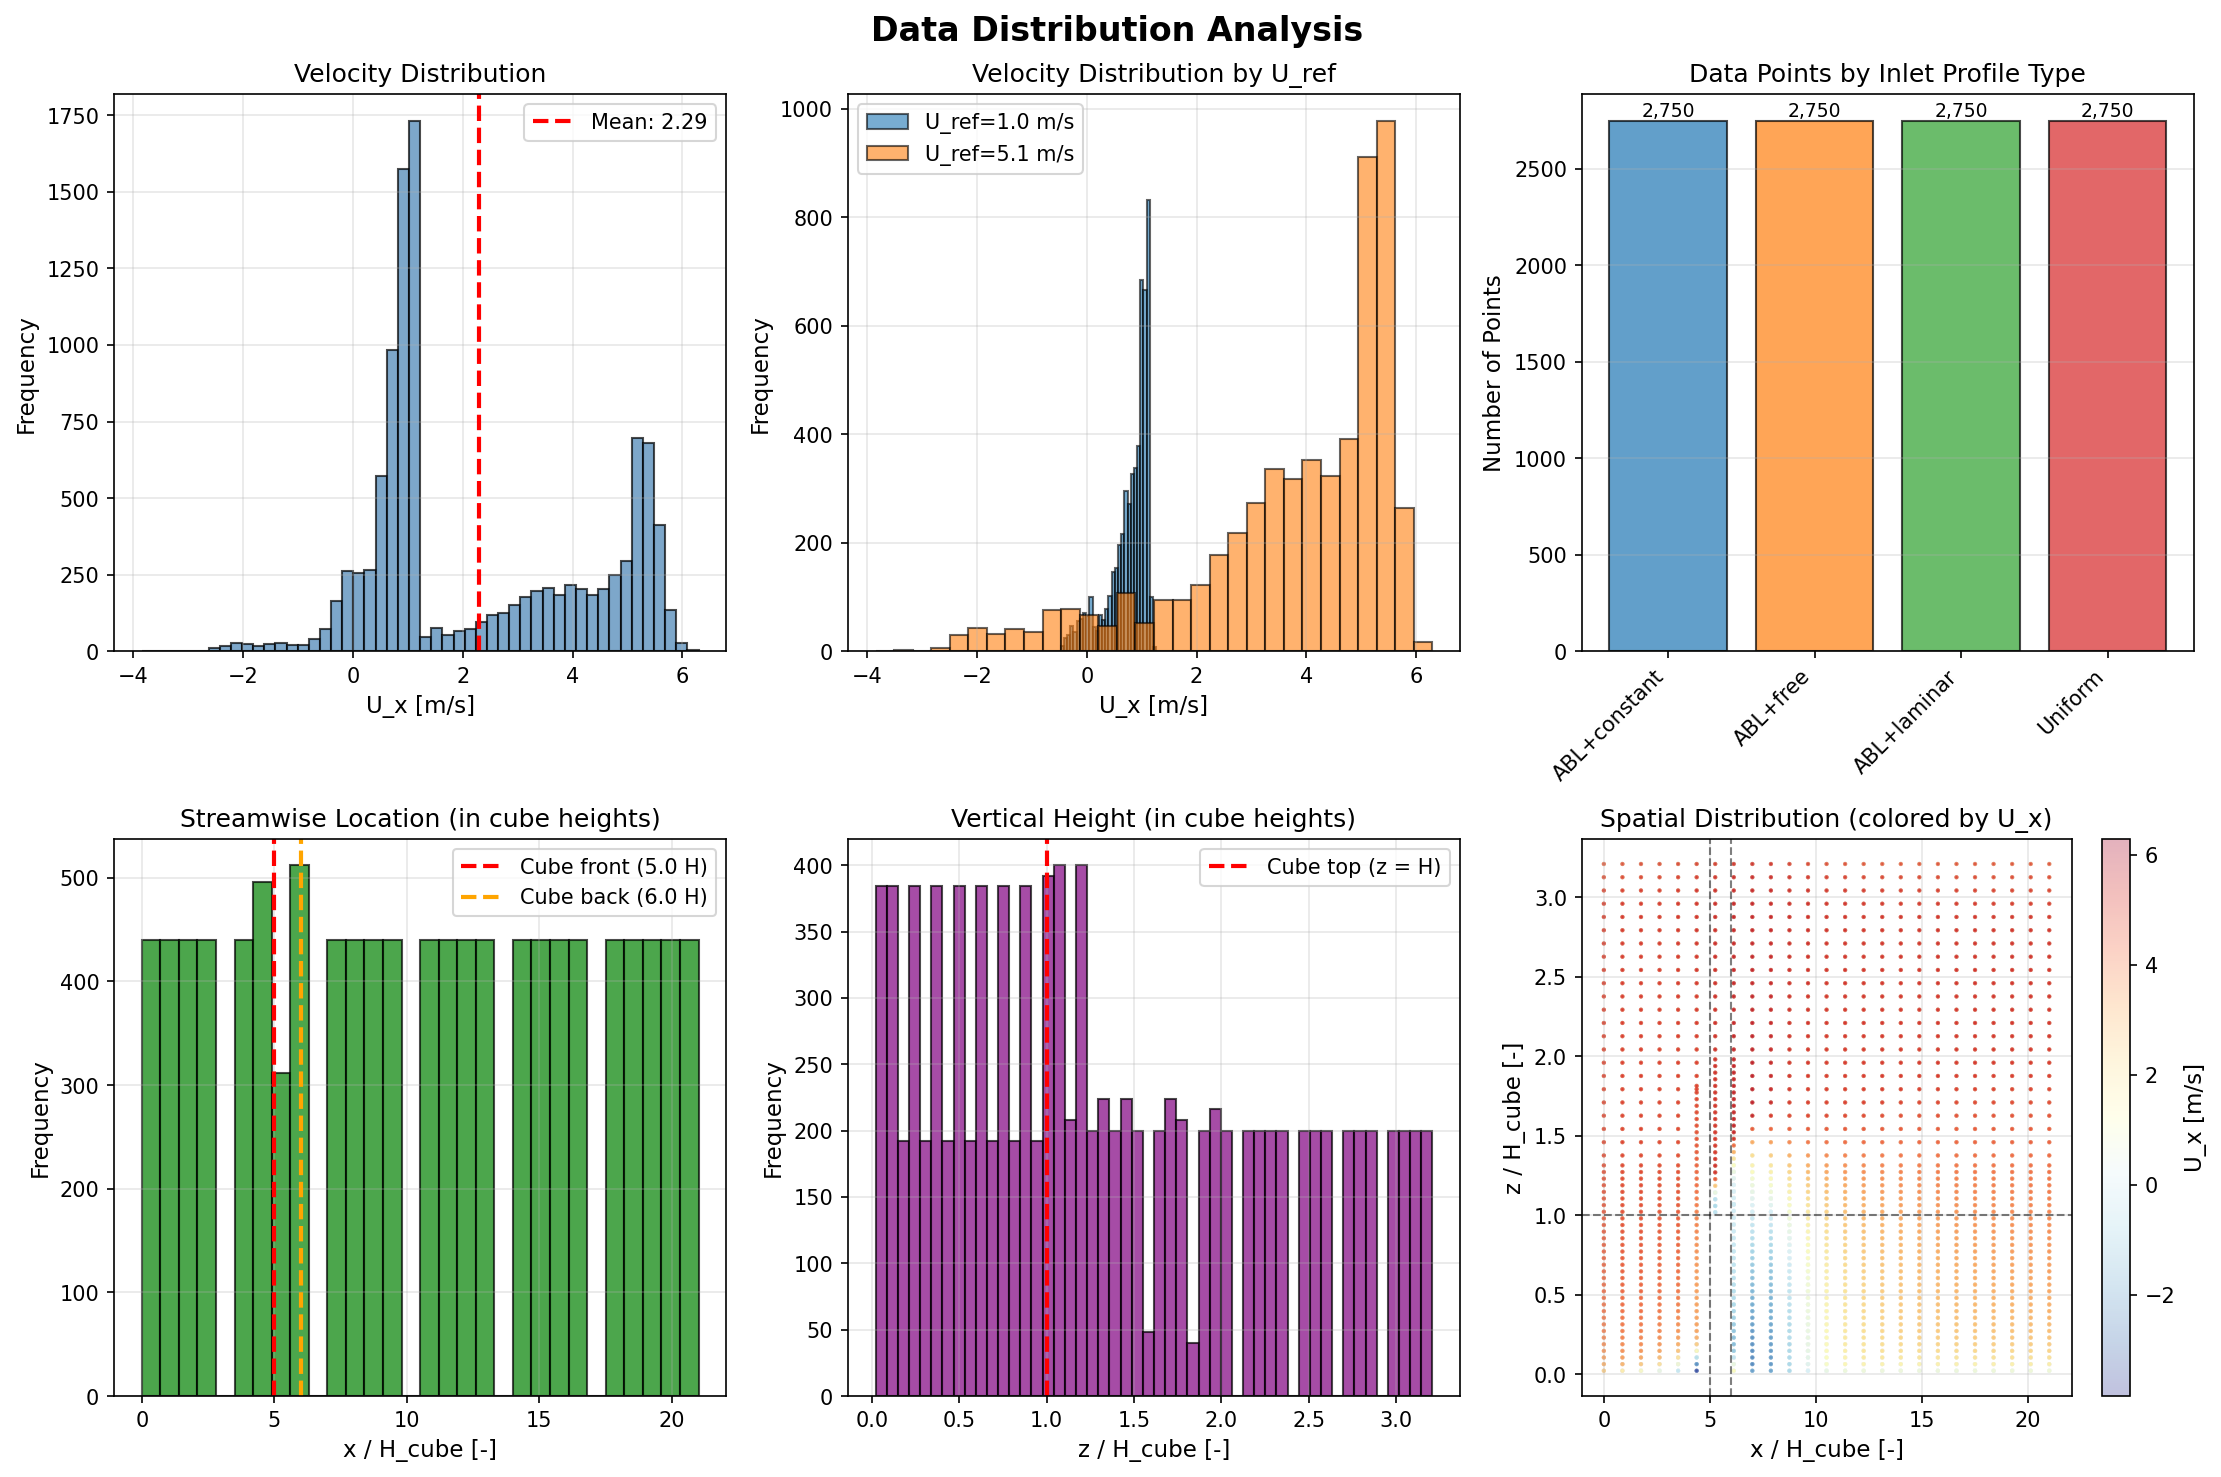

✓ Saved: step2_1_histograms_point_based.png


In [5]:
# ============================================================================
# ANALYSIS 1: HISTOGRAMS
# ============================================================================

print("\n" + "="*80)
print("ANALYSIS 1: HISTOGRAMS")
print("="*80)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Data Distribution Analysis', fontsize=16, fontweight='bold')

# 1.1 Velocity distribution
ax = axes[0, 0]
ax.hist(df['U_x'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
ax.set_xlabel('U_x [m/s]')
ax.set_ylabel('Frequency')
ax.set_title('Velocity Distribution')
ax.grid(True, alpha=0.3)
ax.axvline(df['U_x'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df["U_x"].mean():.2f}')
ax.legend()

# 1.2 U_ref distribution
ax = axes[0, 1]
for u_ref in df['U_ref'].unique():
    subset = df[df['U_ref'] == u_ref]
    ax.hist(subset['U_x'], bins=30, alpha=0.6, label=f'U_ref={u_ref:.1f} m/s', edgecolor='black')
ax.set_xlabel('U_x [m/s]')
ax.set_ylabel('Frequency')
ax.set_title('Velocity Distribution by U_ref')
ax.legend()
ax.grid(True, alpha=0.3)

# 1.3 Profile type distribution
ax = axes[0, 2]
profile_counts = df.groupby('profile_name').size()
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
bars = ax.bar(range(len(profile_counts)), profile_counts.values, color=colors, edgecolor='black', alpha=0.7)
ax.set_xticks(range(len(profile_counts)))
ax.set_xticklabels(profile_counts.index, rotation=45, ha='right')
ax.set_ylabel('Number of Points')
ax.set_title('Data Points by Inlet Profile Type')
ax.grid(True, alpha=0.3, axis='y')

for i, bar in enumerate(bars):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(height):,}', ha='center', va='bottom', fontsize=9)

# 1.4 Stream-wise location (x) - NOW IN CUBE HEIGHTS
ax = axes[1, 0]
ax.hist(df['x_norm'], bins=30, edgecolor='black', alpha=0.7, color='green')
ax.set_xlabel('x / H_cube [-]')
ax.set_ylabel('Frequency')
ax.set_title('Streamwise Location (in cube heights)')
ax.axvline(X_CUBE_FRONT / H_CUBE, color='red', linestyle='--', linewidth=2, label=f'Cube front ({X_CUBE_FRONT/H_CUBE:.1f} H)')
ax.axvline(X_CUBE_BACK / H_CUBE, color='orange', linestyle='--', linewidth=2, label=f'Cube back ({X_CUBE_BACK/H_CUBE:.1f} H)')
ax.legend()
ax.grid(True, alpha=0.3)

# 1.5 Vertical location (z) - IN CUBE HEIGHTS
ax = axes[1, 1]
ax.hist(df['z_norm'], bins=50, edgecolor='black', alpha=0.7, color='purple')
ax.set_xlabel('z / H_cube [-]')
ax.set_ylabel('Frequency')
ax.set_title('Vertical Height (in cube heights)')
ax.axvline(1.0, color='red', linestyle='--', linewidth=2, label='Cube top (z = H)')
ax.legend()
ax.grid(True, alpha=0.3)

# 1.6 2D spatial distribution with flow regimes
ax = axes[1, 2]
scatter = ax.scatter(df['x_norm'], df['z_norm'], c=df['U_x'], s=1, alpha=0.3, cmap='RdYlBu_r')
ax.set_xlabel('x / H_cube [-]')
ax.set_ylabel('z / H_cube [-]')
ax.set_title('Spatial Distribution (colored by U_x)')
ax.axvline(X_CUBE_FRONT / H_CUBE, color='black', linestyle='--', linewidth=1, alpha=0.5)
ax.axvline(X_CUBE_BACK / H_CUBE, color='black', linestyle='--', linewidth=1, alpha=0.5)
ax.axhline(1.0, color='black', linestyle='--', linewidth=1, alpha=0.5)
plt.colorbar(scatter, ax=ax, label='U_x [m/s]')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step2_1_histograms_point_based.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step2_1_histograms_point_based.png")
plt.close()


ANALYSIS 2: PCA - FEATURE IMPORTANCE

What PCA does:
  - Finds directions of maximum variance in your data
  - Shows which features matter most
  - PC1 = direction explaining most variance
  - PC2 = second most important direction (orthogonal to PC1)

PCA Results (using x_norm = x/H_cube):
  Explained variance by component:
    PC1: 25.44%
    PC2: 25.00%
    PC3: 25.00%
    PC4: 24.56%
  Cumulative variance (PC1+PC2): 50.44%


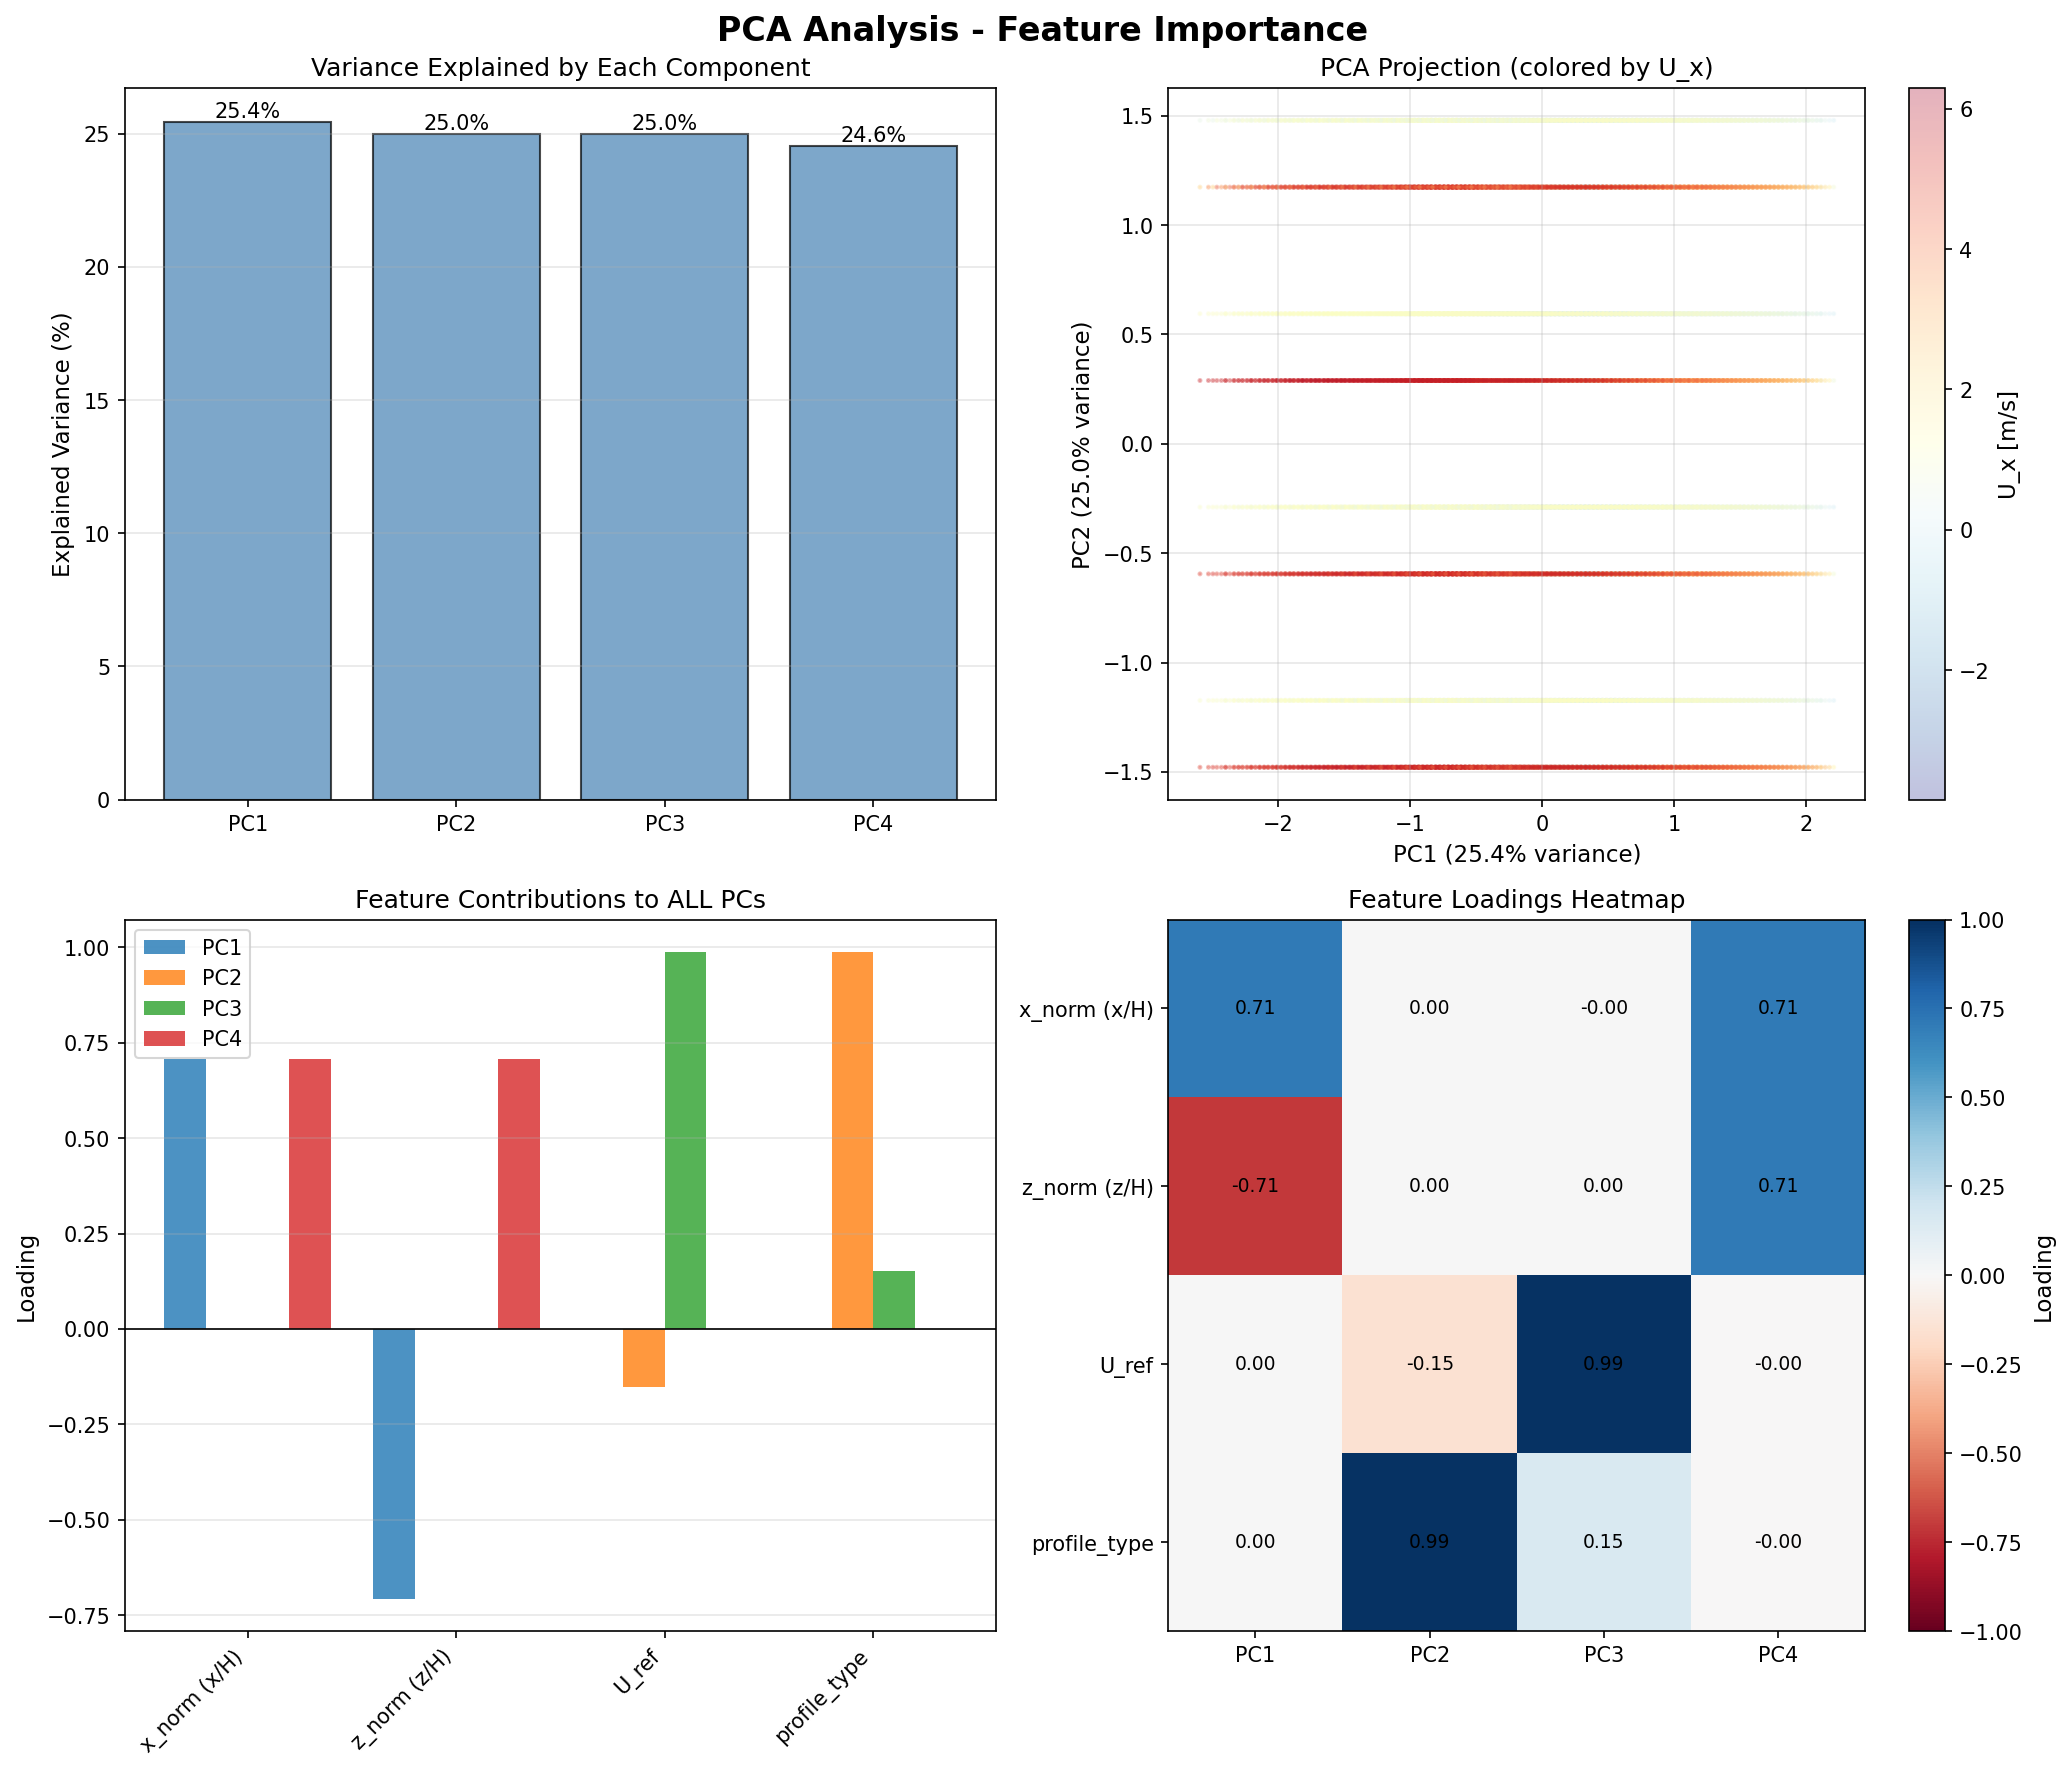

✓ Saved: step2_2_pca_analysis_pointbased.png

Interpretation:
  - PC1: Dominated by x_norm (loading = 0.71)
  - PC2: Dominated by profile_type (loading = 0.99)


In [13]:
# ============================================================================
# ANALYSIS 2: PCA (Principal Component Analysis)
# ============================================================================

print("\n" + "="*80)
print("ANALYSIS 2: PCA - FEATURE IMPORTANCE")
print("="*80)
print("\nWhat PCA does:")
print("  - Finds directions of maximum variance in your data")
print("  - Shows which features matter most")
print("  - PC1 = direction explaining most variance")
print("  - PC2 = second most important direction (orthogonal to PC1)")

# Prepare features for PCA - using physics-based features
# Using: x_norm, z_norm, U_ref, profile_type (NO α, δ!)
features_for_pca = df[['x_norm', 'z_norm', 'U_ref', 'profile_type']].values
target = df['U_x'].values

# Standardize (required for PCA)
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features_for_pca)

# Perform PCA
pca = PCA(n_components=4)
pca_result = pca.fit_transform(features_scaled)

print(f"\nPCA Results (using x_norm = x/H_cube):")
print(f"  Explained variance by component:")
for i, var in enumerate(pca.explained_variance_ratio_):
    print(f"    PC{i+1}: {var*100:.2f}%")
print(f"  Cumulative variance (PC1+PC2): {sum(pca.explained_variance_ratio_[:2])*100:.2f}%")

# Create PCA plots
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('PCA Analysis - Feature Importance', fontsize=16, fontweight='bold')

# 2.1 Explained variance
ax = axes[0, 0]
pc_labels = [f'PC{i+1}' for i in range(len(pca.explained_variance_ratio_))]
bars = ax.bar(pc_labels, pca.explained_variance_ratio_ * 100, 
              edgecolor='black', alpha=0.7, color='steelblue')
ax.set_ylabel('Explained Variance (%)')
ax.set_title('Variance Explained by Each Component')
ax.grid(True, alpha=0.3, axis='y')

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.1f}%', ha='center', va='bottom')

# 2.2 PCA projection colored by velocity
ax = axes[0, 1]
scatter = ax.scatter(pca_result[:, 0], pca_result[:, 1], 
                     c=target, s=2, alpha=0.3, cmap='RdYlBu_r')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
ax.set_title('PCA Projection (colored by U_x)')
plt.colorbar(scatter, ax=ax, label='U_x [m/s]')
ax.grid(True, alpha=0.3)

# 2.3 Feature loadings
ax = axes[1, 0]
feature_names = ['x_norm (x/H)', 'z_norm (z/H)', 'U_ref', 'profile_type']
loadings_all = pca.components_.T

x_pos = np.arange(len(feature_names))
width = 0.2

for i in range(4):
    offset = (i - 1.5) * width
    ax.bar(x_pos + offset, loadings_all[:, i], width, 
           label=f'PC{i+1}', alpha=0.8)

ax.set_ylabel('Loading')
ax.set_title('Feature Contributions to ALL PCs')
ax.set_xticks(x_pos)
ax.set_xticklabels(feature_names, rotation=45, ha='right')
ax.axhline(0, color='black', linewidth=0.8)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

# 2.4 Loadings heatmap
ax = axes[1, 1]
im = ax.imshow(loadings_all, cmap='RdBu', aspect='auto', vmin=-1, vmax=1)
ax.set_xticks(range(4))
ax.set_xticklabels([f'PC{i+1}' for i in range(4)])
ax.set_yticks(range(len(feature_names)))
ax.set_yticklabels(feature_names)
ax.set_title('Feature Loadings Heatmap')

for i in range(len(feature_names)):
    for j in range(4):
        text = ax.text(j, i, f'{loadings_all[i, j]:.2f}',
                      ha="center", va="center", color="black", fontsize=9)

plt.colorbar(im, ax=ax, label='Loading')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step2_2_pca_analysis_pointbased.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step2_2_pca_analysis_pointbased.png")
plt.close()

feature_names_short = ['x_norm', 'z_norm', 'U_ref', 'profile_type']
print("\nInterpretation:")
print(f"  - PC1: Dominated by {feature_names_short[np.argmax(np.abs(loadings_all[:, 0]))]} "
      f"(loading = {loadings_all[np.argmax(np.abs(loadings_all[:, 0])), 0]:.2f})")
print(f"  - PC2: Dominated by {feature_names_short[np.argmax(np.abs(loadings_all[:, 1]))]} "
      f"(loading = {loadings_all[np.argmax(np.abs(loadings_all[:, 1])), 1]:.2f})")



ANALYSIS 3: t-SNE - CLUSTERING VISUALIZATION

What t-SNE does:
  - Reduces high-dimensional data to 2D while preserving local structure
  - Shows if data naturally forms clusters
  - Nearby points in 2D were nearby in original space

Running t-SNE on 5,000 sampled points...
  (This may take 30-60 seconds...)
✓ t-SNE complete


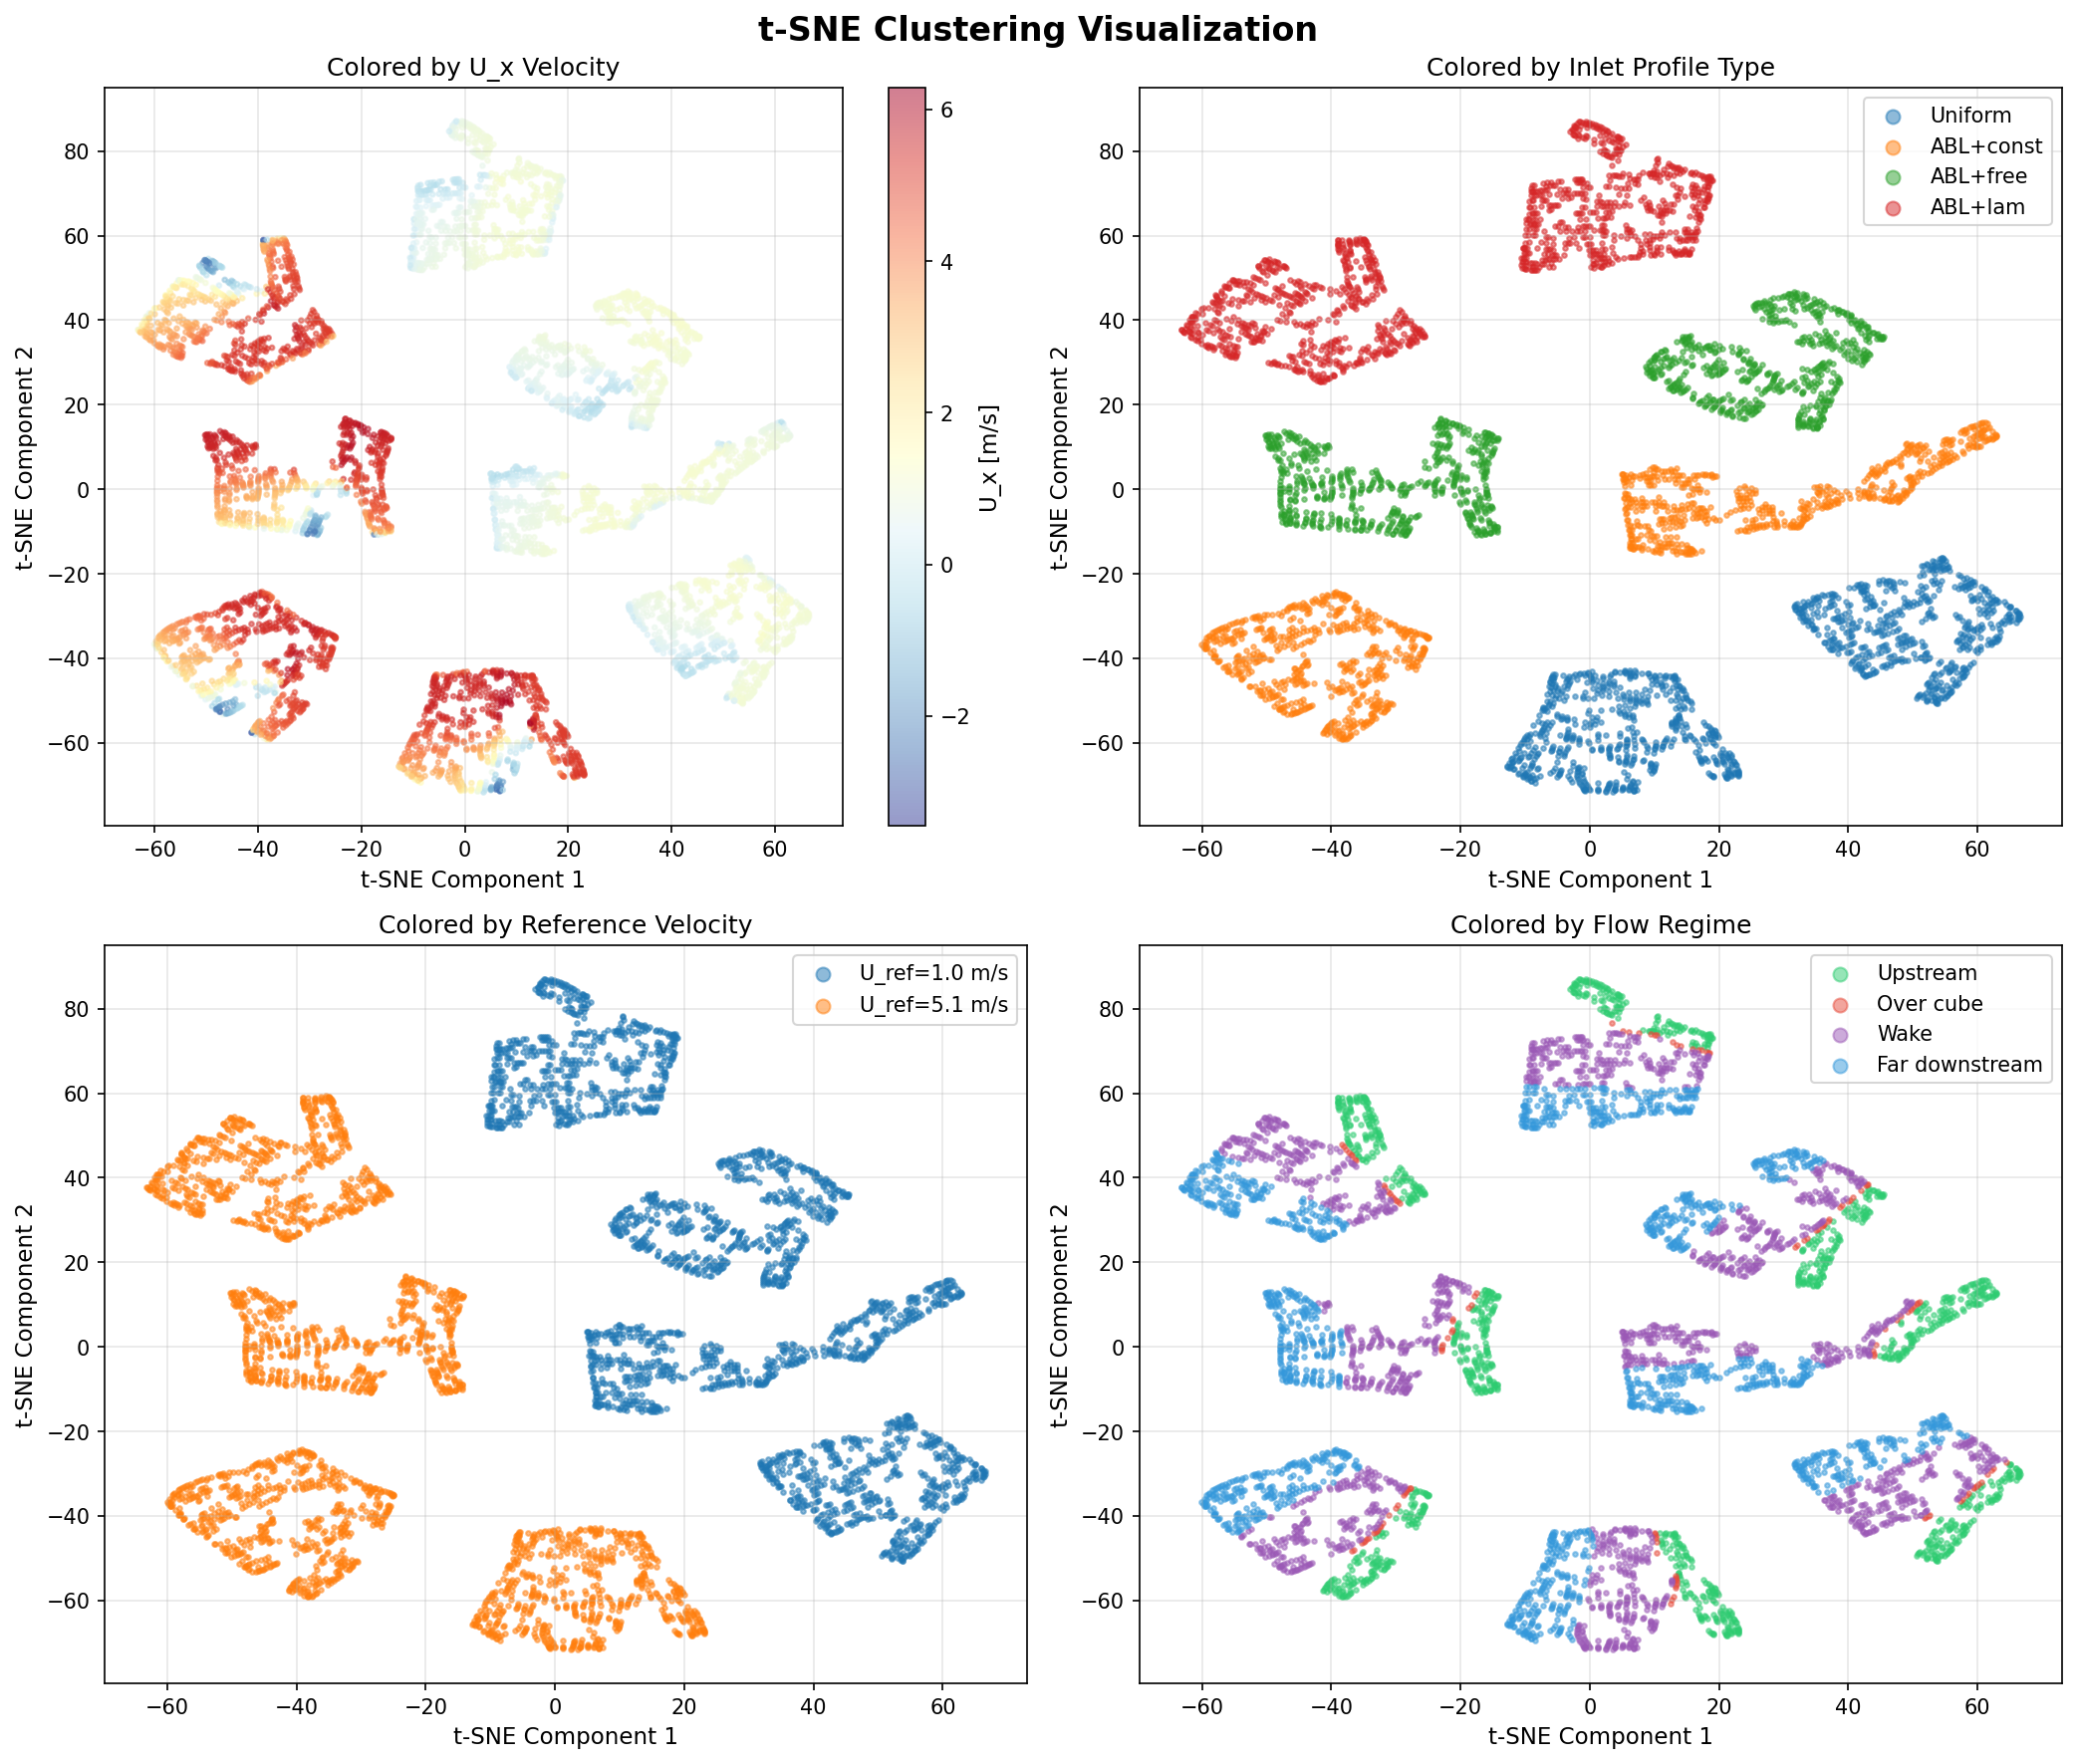

✓ Saved: step2_3_tsne_clustering.png

Interpretation:
  - If you see distinct clusters → different flow regimes
  - If well-mixed → smooth transitions between cases
  - Look for: profile types separating, U_ref separating, flow regimes separating


In [7]:
# ============================================================================
# ANALYSIS 3: t-SNE (Clustering Visualization)
# ============================================================================

print("\n" + "="*80)
print("ANALYSIS 3: t-SNE - CLUSTERING VISUALIZATION")
print("="*80)
print("\nWhat t-SNE does:")
print("  - Reduces high-dimensional data to 2D while preserving local structure")
print("  - Shows if data naturally forms clusters")
print("  - Nearby points in 2D were nearby in original space")

# Sample data for t-SNE
n_sample = min(5000, len(df))
sample_idx = np.random.choice(len(df), n_sample, replace=False)

features_tsne = features_scaled[sample_idx]
target_tsne = target[sample_idx]
profile_types_tsne = df['profile_type'].values[sample_idx]
u_ref_tsne = df['U_ref'].values[sample_idx]
flow_regime_tsne = df['flow_regime'].values[sample_idx]

print(f"\nRunning t-SNE on {n_sample:,} sampled points...")
print("  (This may take 30-60 seconds...)")

tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
tsne_result = tsne.fit_transform(features_tsne)

print("✓ t-SNE complete")

# Create t-SNE plots - now with 4 panels including flow regime
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('t-SNE Clustering Visualization', fontsize=16, fontweight='bold')

# 3.1 Colored by velocity
ax = axes[0, 0]
scatter = ax.scatter(tsne_result[:, 0], tsne_result[:, 1], 
                     c=target_tsne, s=5, alpha=0.5, cmap='RdYlBu_r')
ax.set_xlabel('t-SNE Component 1')
ax.set_ylabel('t-SNE Component 2')
ax.set_title('Colored by U_x Velocity')
plt.colorbar(scatter, ax=ax, label='U_x [m/s]')
ax.grid(True, alpha=0.3)

# 3.2 Colored by profile type
ax = axes[0, 1]
profile_names_map = {0: 'Uniform', 1: 'ABL+const', 2: 'ABL+free', 3: 'ABL+lam'}
colors_map = {0: '#1f77b4', 1: '#ff7f0e', 2: '#2ca02c', 3: '#d62728'}

for ptype in np.unique(profile_types_tsne):
    mask = profile_types_tsne == ptype
    ax.scatter(tsne_result[mask, 0], tsne_result[mask, 1], 
               c=colors_map[ptype], s=5, alpha=0.5, 
               label=profile_names_map[ptype])

ax.set_xlabel('t-SNE Component 1')
ax.set_ylabel('t-SNE Component 2')
ax.set_title('Colored by Inlet Profile Type')
ax.legend(markerscale=3)
ax.grid(True, alpha=0.3)

# 3.3 Colored by U_ref
ax = axes[1, 0]
for u_ref in np.unique(u_ref_tsne):
    mask = u_ref_tsne == u_ref
    ax.scatter(tsne_result[mask, 0], tsne_result[mask, 1], 
               s=5, alpha=0.5, label=f'U_ref={u_ref:.1f} m/s')

ax.set_xlabel('t-SNE Component 1')
ax.set_ylabel('t-SNE Component 2')
ax.set_title('Colored by Reference Velocity')
ax.legend(markerscale=3)
ax.grid(True, alpha=0.3)

# 3.4 NEW: Colored by flow regime
ax = axes[1, 1]
regime_names_map = {0: 'Upstream', 1: 'Over cube', 2: 'Wake', 3: 'Far downstream'}
regime_colors = {0: '#2ecc71', 1: '#e74c3c', 2: '#9b59b6', 3: '#3498db'}

for regime in np.unique(flow_regime_tsne):
    mask = flow_regime_tsne == regime
    ax.scatter(tsne_result[mask, 0], tsne_result[mask, 1], 
               c=regime_colors[regime], s=5, alpha=0.5, 
               label=regime_names_map[regime])

ax.set_xlabel('t-SNE Component 1')
ax.set_ylabel('t-SNE Component 2')
ax.set_title('Colored by Flow Regime')
ax.legend(markerscale=3)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step2_3_tsne_clustering.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step2_3_tsne_clustering.png")
plt.close()

print("\nInterpretation:")
print("  - If you see distinct clusters → different flow regimes")
print("  - If well-mixed → smooth transitions between cases")
print("  - Look for: profile types separating, U_ref separating, flow regimes separating")



ANALYSIS 4: MUTUAL INFORMATION - FEATURE COMPARISON

What Mutual Information (MI) measures:
  - How much knowing input X reduces uncertainty about output Y
  - MI = 0: independent variables
  - MI > 0: correlated (higher = stronger relationship)
  - Unlike correlation, captures non-linear relationships

Comparing different feature sets:

1. ORIGINAL FEATURES (x/H_cube normalization):
   x_norm         : 0.4857
   z_norm         : 0.9008
   U_ref          : 0.5893
   profile_type   : 0.0723

2. WITH WAKE_DISTANCE:
   x_norm         : 0.4835
   z_norm         : 0.9003
   U_ref          : 0.5885
   profile_type   : 0.0712
   wake_distance  : 0.4236

3. WITH FLOW_REGIME (categorical):
   x_norm         : 0.4835
   z_norm         : 0.9003
   U_ref          : 0.5885
   profile_type   : 0.0712
   flow_regime    : 0.3306

4. DISTANCE FROM CUBE FRONT (x_dist_front):
   x_dist_front   : 0.4856
   z_norm         : 0.9008
   U_ref          : 0.5893
   profile_type   : 0.0723


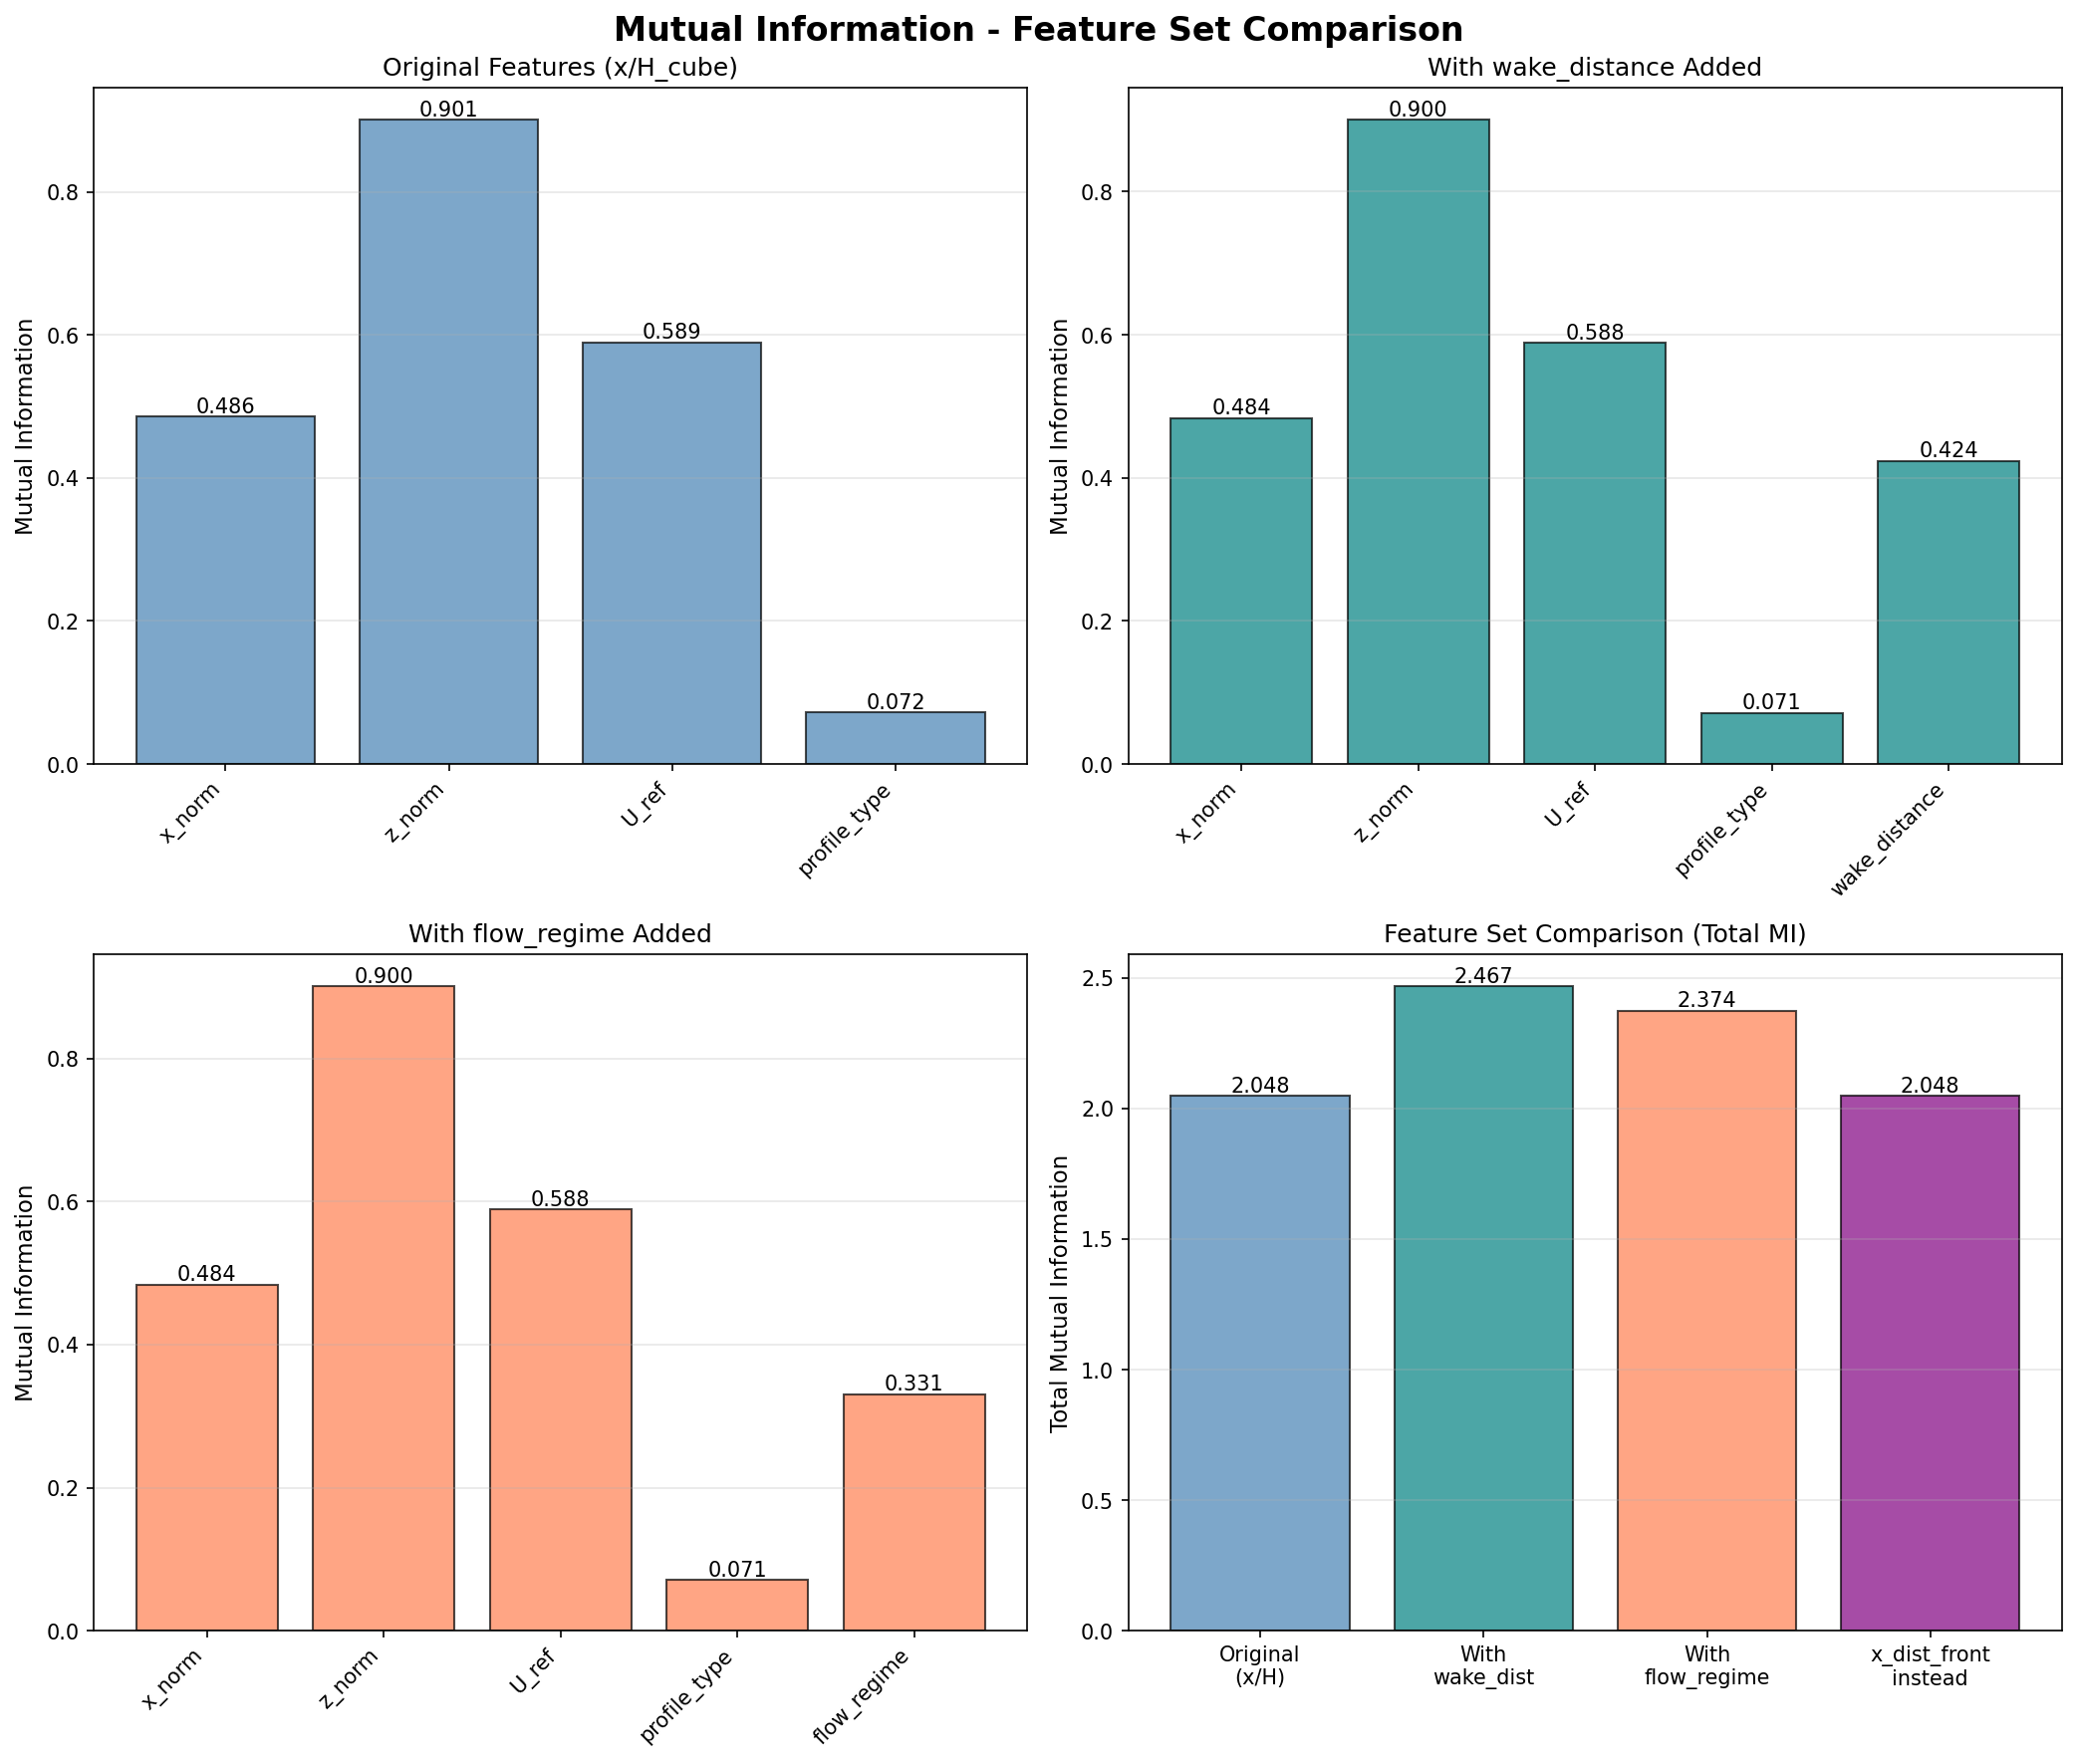

✓ Saved: step2_4_mutual_information_comparison.png

Normalized MI (relative importance) - Recommended features:
  x_norm         : 23.71%
  z_norm         : 43.98%
  U_ref          : 28.77%
  profile_type   : 3.53%

🎯 FEATURE RECOMMENDATION:
  wake_distance MI: 0.4236
  flow_regime MI: 0.3306
  → wake_distance ADDS useful information!
  → flow_regime ADDS useful information!


In [8]:
# ============================================================================
# ANALYSIS 4: MUTUAL INFORMATION - COMPARING FEATURE SETS
# ============================================================================

print("\n" + "="*80)
print("ANALYSIS 4: MUTUAL INFORMATION - FEATURE COMPARISON")
print("="*80)
print("\nWhat Mutual Information (MI) measures:")
print("  - How much knowing input X reduces uncertainty about output Y")
print("  - MI = 0: independent variables")
print("  - MI > 0: correlated (higher = stronger relationship)")
print("  - Unlike correlation, captures non-linear relationships")

print("\nComparing different feature sets:")

# Feature set 1: Original (x_norm, z_norm, U_ref, profile_type)
feature_names_1 = ['x_norm', 'z_norm', 'U_ref', 'profile_type']
features_1 = df[feature_names_1].values
mi_scores_1 = mutual_info_regression(features_1, target, random_state=42)

print(f"\n1. ORIGINAL FEATURES (x/H_cube normalization):")
for fname, score in zip(feature_names_1, mi_scores_1):
    print(f"   {fname:15s}: {score:.4f}")

# Feature set 2: With wake_distance
feature_names_2 = ['x_norm', 'z_norm', 'U_ref', 'profile_type', 'wake_distance']
features_2 = df[feature_names_2].values
mi_scores_2 = mutual_info_regression(features_2, target, random_state=42)

print(f"\n2. WITH WAKE_DISTANCE:")
for fname, score in zip(feature_names_2, mi_scores_2):
    print(f"   {fname:15s}: {score:.4f}")

# Feature set 3: With flow_regime
feature_names_3 = ['x_norm', 'z_norm', 'U_ref', 'profile_type', 'flow_regime']
features_3 = df[feature_names_3].values
mi_scores_3 = mutual_info_regression(features_3, target, random_state=42)

print(f"\n3. WITH FLOW_REGIME (categorical):")
for fname, score in zip(feature_names_3, mi_scores_3):
    print(f"   {fname:15s}: {score:.4f}")

# Feature set 4: x_dist_front instead of x_norm
feature_names_4 = ['x_dist_front', 'z_norm', 'U_ref', 'profile_type']
features_4 = df[feature_names_4].values
mi_scores_4 = mutual_info_regression(features_4, target, random_state=42)

print(f"\n4. DISTANCE FROM CUBE FRONT (x_dist_front):")
for fname, score in zip(feature_names_4, mi_scores_4):
    print(f"   {fname:15s}: {score:.4f}")

# Create comparison plot
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('Mutual Information - Feature Set Comparison', fontsize=16, fontweight='bold')

# 4.1 Original features
ax = axes[0, 0]
mi_norm_1 = mi_scores_1 / mi_scores_1.sum()
bars = ax.bar(feature_names_1, mi_scores_1, edgecolor='black', alpha=0.7, color='steelblue')
ax.set_ylabel('Mutual Information')
ax.set_title('Original Features (x/H_cube)')
ax.set_xticklabels(feature_names_1, rotation=45, ha='right')
ax.grid(True, alpha=0.3, axis='y')
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height, f'{height:.3f}', ha='center', va='bottom')

# 4.2 With wake_distance
ax = axes[0, 1]
bars = ax.bar(feature_names_2, mi_scores_2, edgecolor='black', alpha=0.7, color='teal')
ax.set_ylabel('Mutual Information')
ax.set_title('With wake_distance Added')
ax.set_xticklabels(feature_names_2, rotation=45, ha='right')
ax.grid(True, alpha=0.3, axis='y')
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height, f'{height:.3f}', ha='center', va='bottom')

# 4.3 With flow_regime
ax = axes[1, 0]
bars = ax.bar(feature_names_3, mi_scores_3, edgecolor='black', alpha=0.7, color='coral')
ax.set_ylabel('Mutual Information')
ax.set_title('With flow_regime Added')
ax.set_xticklabels(feature_names_3, rotation=45, ha='right')
ax.grid(True, alpha=0.3, axis='y')
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height, f'{height:.3f}', ha='center', va='bottom')

# 4.4 Comparison summary (normalized MI)
ax = axes[1, 1]
# Total MI for each feature set
total_mi = [sum(mi_scores_1), sum(mi_scores_2), sum(mi_scores_3), sum(mi_scores_4)]
feature_set_names = ['Original\n(x/H)', 'With\nwake_dist', 'With\nflow_regime', 'x_dist_front\ninstead']
colors_bar = ['steelblue', 'teal', 'coral', 'purple']
bars = ax.bar(feature_set_names, total_mi, edgecolor='black', alpha=0.7, color=colors_bar)
ax.set_ylabel('Total Mutual Information')
ax.set_title('Feature Set Comparison (Total MI)')
ax.grid(True, alpha=0.3, axis='y')
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height, f'{height:.3f}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step2_4_mutual_information_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step2_4_mutual_information_comparison.png")
plt.close()

# Normalized MI for recommended feature set
mi_normalized = mi_scores_1 / mi_scores_1.sum()
print(f"\nNormalized MI (relative importance) - Recommended features:")
for fname, score in zip(feature_names_1, mi_normalized):
    print(f"  {fname:15s}: {score*100:.2f}%")

print("\n🎯 FEATURE RECOMMENDATION:")
print(f"  wake_distance MI: {mi_scores_2[4]:.4f}")
print(f"  flow_regime MI: {mi_scores_3[4]:.4f}")
if mi_scores_2[4] > 0.05:
    print("  → wake_distance ADDS useful information!")
else:
    print("  → wake_distance is REDUNDANT with x_norm (skip it)")
if mi_scores_3[4] > 0.05:
    print("  → flow_regime ADDS useful information!")
else:
    print("  → flow_regime is REDUNDANT with x_norm (skip it)")



ANALYSIS 5: CORRELATION MATRIX

Correlation matrix:
               x_norm  z_norm  U_ref  profile_type  wake_distance  \
x_norm          1.000  -0.018  0.000         0.000          0.973   
z_norm         -0.018   1.000  0.000         0.000         -0.023   
U_ref           0.000   0.000  1.000         0.000          0.000   
profile_type    0.000   0.000  0.000         1.000         -0.000   
wake_distance   0.973  -0.023  0.000        -0.000          1.000   
flow_regime     0.919  -0.015  0.000        -0.000          0.841   
U_x             0.000   0.364  0.742        -0.035          0.047   

               flow_regime    U_x  
x_norm               0.919  0.000  
z_norm              -0.015  0.364  
U_ref                0.000  0.742  
profile_type        -0.000 -0.035  
wake_distance        0.841  0.047  
flow_regime          1.000 -0.074  
U_x                 -0.074  1.000  


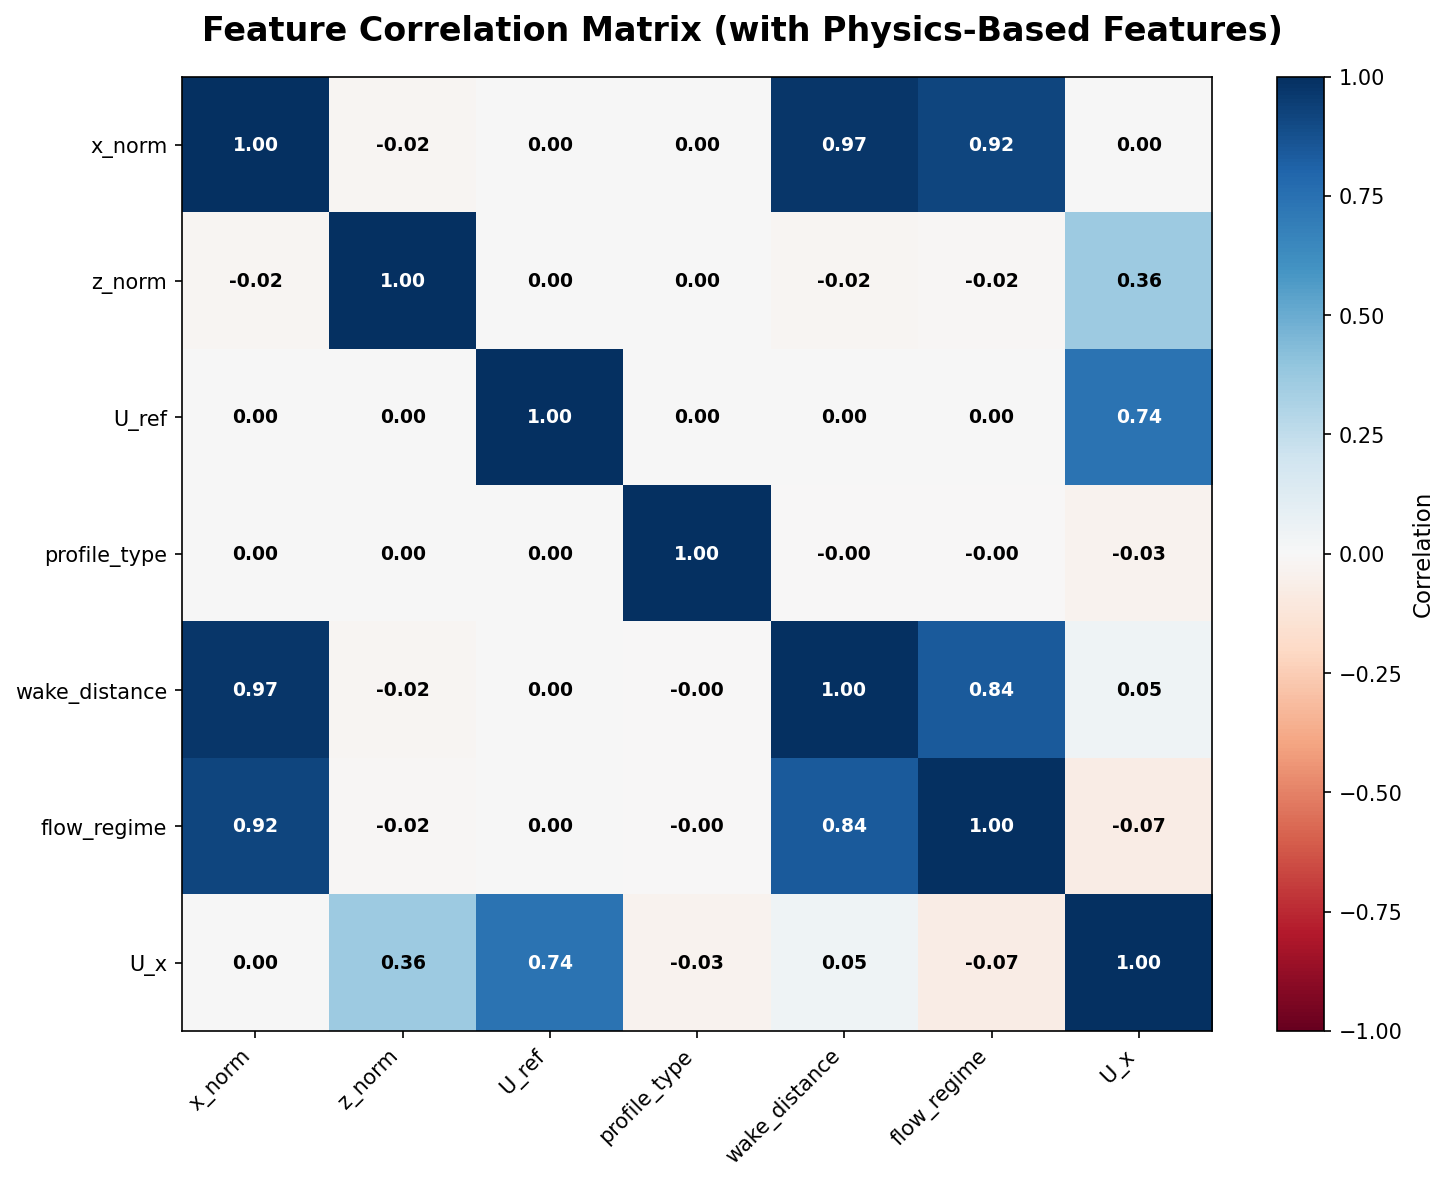

✓ Saved: step2_5_correlation_matrix_pointbased.png

🔍 CHECKING FOR REDUNDANT FEATURES:
  x_norm ↔ wake_distance: 0.973
  x_norm ↔ flow_regime: 0.919
  wake_distance ↔ flow_regime: 0.841
  ⚠️ wake_distance is highly correlated with x_norm - likely redundant!
  ⚠️ flow_regime is highly correlated with x_norm - likely redundant!


In [9]:
# ============================================================================
# ANALYSIS 5: CORRELATION MATRIX 
# ============================================================================

print(f"\n{'='*80}")
print("ANALYSIS 5: CORRELATION MATRIX")
print("="*80)

# Create correlation matrix with new features
corr_features = df[['x_norm', 'z_norm', 'U_ref', 'profile_type', 'wake_distance', 'flow_regime', 'U_x']]
corr_matrix = corr_features.corr()

print("\nCorrelation matrix:")
print(corr_matrix.round(3))

fig, ax = plt.subplots(1, 1, figsize=(10, 8))
fig.suptitle('Feature Correlation Matrix (with Physics-Based Features)', fontsize=16, fontweight='bold')

im = ax.imshow(corr_matrix, cmap='RdBu', aspect='auto', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr_matrix.columns)))
ax.set_yticklabels(corr_matrix.columns)

for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        text = ax.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}',
                      ha="center", va="center", 
                      color="white" if abs(corr_matrix.iloc[i, j]) > 0.5 else "black",
                      fontsize=9, fontweight='bold')

plt.colorbar(im, ax=ax, label='Correlation')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step2_5_correlation_matrix_pointbased.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step2_5_correlation_matrix_pointbased.png")
plt.close()

# Check for redundant features
print("\n🔍 CHECKING FOR REDUNDANT FEATURES:")
print(f"  x_norm ↔ wake_distance: {corr_matrix.loc['x_norm', 'wake_distance']:.3f}")
print(f"  x_norm ↔ flow_regime: {corr_matrix.loc['x_norm', 'flow_regime']:.3f}")
print(f"  wake_distance ↔ flow_regime: {corr_matrix.loc['wake_distance', 'flow_regime']:.3f}")

if abs(corr_matrix.loc['x_norm', 'wake_distance']) > 0.8:
    print("  ⚠️ wake_distance is highly correlated with x_norm - likely redundant!")
if abs(corr_matrix.loc['x_norm', 'flow_regime']) > 0.8:
    print("  ⚠️ flow_regime is highly correlated with x_norm - likely redundant!")



ANALYSIS 6: CONDITIONAL ENTROPY - FEATURE SET COMPARISON

What Conditional Entropy measures:
  - H(U_x | inputs) = remaining uncertainty about U_x after knowing inputs
  - Low entropy → deterministic (predictable)
  - High entropy → stochastic (noisy/unpredictable)
  - Tells you: Can we even hope to predict this accurately?

Unconditional entropy H(U_x): 3.7313 bits

Conditional entropy with single features:
  H(U_x | x_norm         ): 3.2591 bits  (reduces by 0.4722 = 12.7%)
  H(U_x | z_norm         ): 2.9020 bits  (reduces by 0.8292 = 22.2%)
  H(U_x | U_ref          ): 2.8889 bits  (reduces by 0.8423 = 22.6%)
  H(U_x | profile_type   ): 3.6872 bits  (reduces by 0.0440 = 1.2%)
  H(U_x | wake_distance  ): 3.3704 bits  (reduces by 0.3608 = 9.7%)
  H(U_x | flow_regime    ): 3.4431 bits  (reduces by 0.2882 = 7.7%)

Combined feature sets:
  Set 1 (x_norm, z_norm, U_ref, profile_type): 0.3915 bits (89.5% reduction)
  Set 2 (+ wake_distance): 0.3586 bits (90.4% reduction)
  Set 3 (+ flow_re

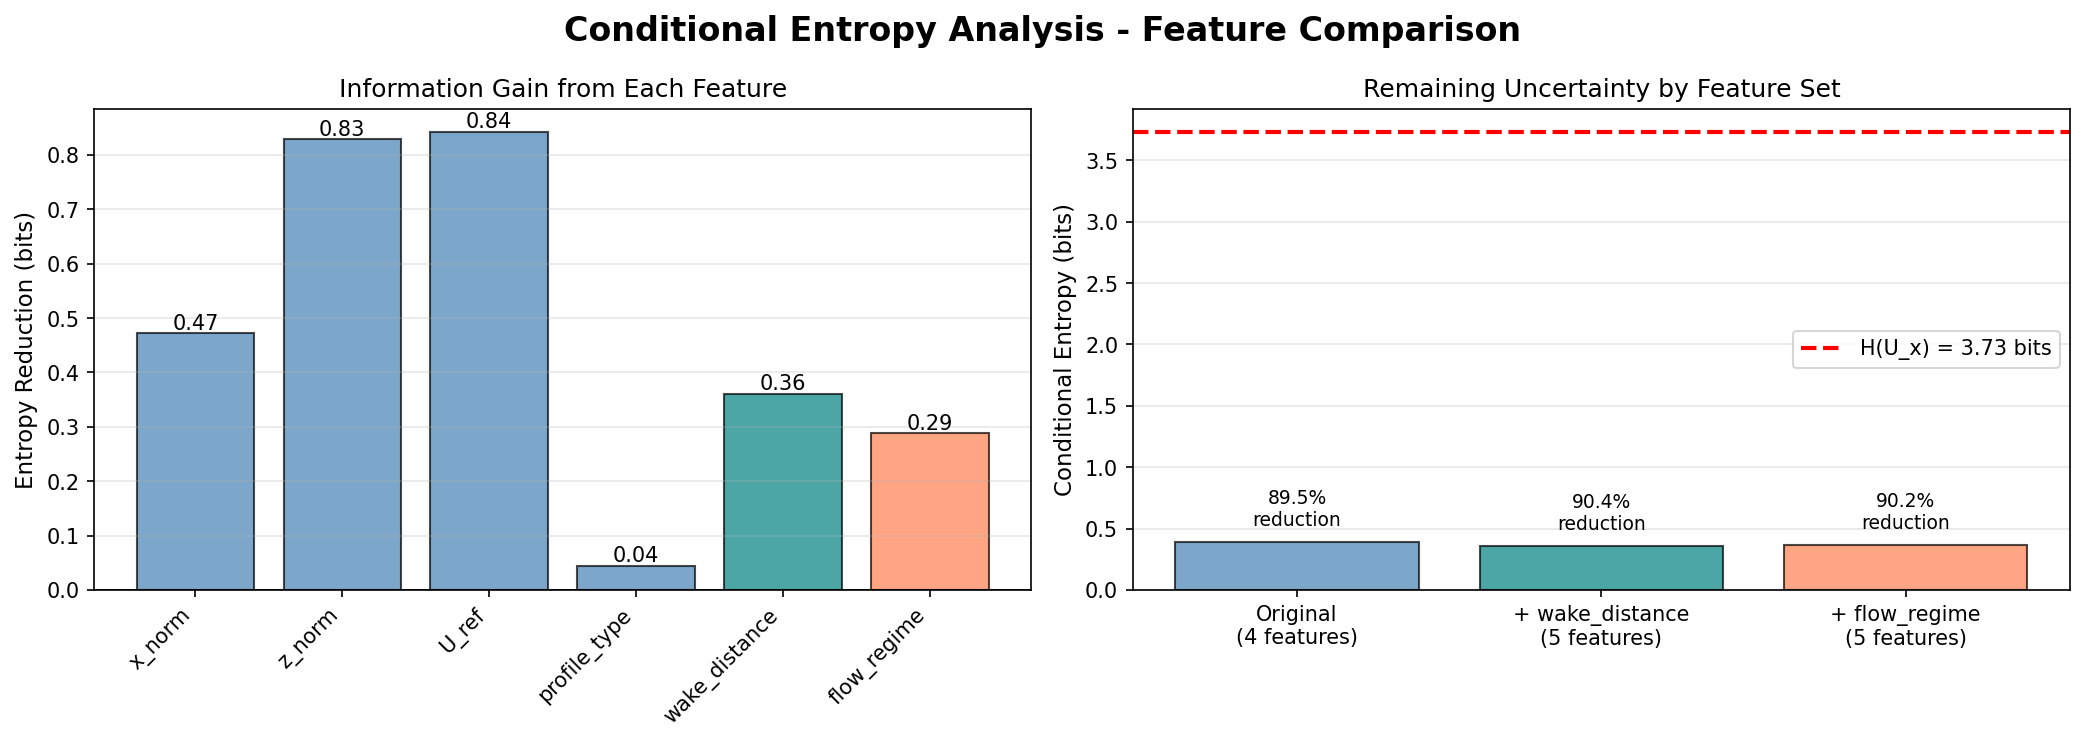

✓ Saved: step2_6_conditional_entropy_comparison.png

🎯 ENTROPY ANALYSIS CONCLUSIONS:
  Original features reduce entropy by: 89.5%
  Adding wake_distance: 90.4% (improvement: 0.88%)
  Adding flow_regime: 90.2% (improvement: 0.72%)
  → wake_distance provides NEGLIGIBLE improvement - SKIP IT
  → flow_regime provides NEGLIGIBLE improvement - SKIP IT


In [10]:
# ============================================================================
# ANALYSIS 6: CONDITIONAL ENTROPY - COMPARING FEATURE SETS
# ============================================================================

print("\n" + "="*80)
print("ANALYSIS 6: CONDITIONAL ENTROPY - FEATURE SET COMPARISON")
print("="*80)
print("\nWhat Conditional Entropy measures:")
print("  - H(U_x | inputs) = remaining uncertainty about U_x after knowing inputs")
print("  - Low entropy → deterministic (predictable)")
print("  - High entropy → stochastic (noisy/unpredictable)")
print("  - Tells you: Can we even hope to predict this accurately?")

def discretize(data, n_bins=20):
    """Discretize continuous data into bins"""
    return pd.cut(data, bins=n_bins, labels=False, duplicates='drop')

def calculate_entropy(data):
    """Calculate Shannon entropy"""
    data_clean = data[~pd.isna(data)]
    value_counts = pd.Series(data_clean).value_counts()
    probabilities = value_counts / len(data_clean)
    return -np.sum(probabilities * np.log2(probabilities + 1e-10))

def calculate_conditional_entropy(target_discrete, feature_discrete):
    """Calculate H(Y|X)"""
    conditional_entropy = 0
    for feat_val in np.unique(feature_discrete):
        mask = feature_discrete == feat_val
        if mask.sum() > 0:
            prob = mask.sum() / len(feature_discrete)
            H_given_feat = calculate_entropy(target_discrete[mask])
            conditional_entropy += prob * H_given_feat
    return conditional_entropy

# Discretize output
U_x_discrete = discretize(df['U_x'].values, n_bins=30)

# Calculate unconditional entropy
H_Ux = calculate_entropy(U_x_discrete)
print(f"\nUnconditional entropy H(U_x): {H_Ux:.4f} bits")

# Single feature analysis
print(f"\nConditional entropy with single features:")
single_feature_results = []

for feat_name in ['x_norm', 'z_norm', 'U_ref', 'profile_type', 'wake_distance', 'flow_regime']:
    feat_discrete = discretize(df[feat_name].values, n_bins=20)
    conditional_entropy = calculate_conditional_entropy(U_x_discrete, feat_discrete)
    reduction = H_Ux - conditional_entropy
    reduction_pct = (reduction / H_Ux) * 100
    
    single_feature_results.append({
        'feature': feat_name,
        'H_conditional': conditional_entropy,
        'reduction': reduction,
        'reduction_pct': reduction_pct
    })
    
    print(f"  H(U_x | {feat_name:15s}): {conditional_entropy:.4f} bits  "
          f"(reduces by {reduction:.4f} = {reduction_pct:.1f}%)")

# Combined features - Original set
print(f"\nCombined feature sets:")

def combine_features_for_entropy(df, feature_list):
    """Combine multiple features for conditional entropy calculation"""
    combined = None
    for feat in feature_list:
        feat_discrete = discretize(df[feat].values, n_bins=20)
        feat_str = pd.Series(feat_discrete).astype(str)
        if combined is None:
            combined = feat_str
        else:
            combined = combined + '_' + feat_str
    return combined

# Set 1: Original
combined_1 = combine_features_for_entropy(df, ['x_norm', 'z_norm', 'U_ref', 'profile_type'])
H_cond_1 = calculate_conditional_entropy(U_x_discrete, combined_1.values)
reduction_1 = H_Ux - H_cond_1
reduction_pct_1 = (reduction_1 / H_Ux) * 100
print(f"  Set 1 (x_norm, z_norm, U_ref, profile_type): {H_cond_1:.4f} bits ({reduction_pct_1:.1f}% reduction)")

# Set 2: With wake_distance
combined_2 = combine_features_for_entropy(df, ['x_norm', 'z_norm', 'U_ref', 'profile_type', 'wake_distance'])
H_cond_2 = calculate_conditional_entropy(U_x_discrete, combined_2.values)
reduction_2 = H_Ux - H_cond_2
reduction_pct_2 = (reduction_2 / H_Ux) * 100
print(f"  Set 2 (+ wake_distance): {H_cond_2:.4f} bits ({reduction_pct_2:.1f}% reduction)")

# Set 3: With flow_regime
combined_3 = combine_features_for_entropy(df, ['x_norm', 'z_norm', 'U_ref', 'profile_type', 'flow_regime'])
H_cond_3 = calculate_conditional_entropy(U_x_discrete, combined_3.values)
reduction_3 = H_Ux - H_cond_3
reduction_pct_3 = (reduction_3 / H_Ux) * 100
print(f"  Set 3 (+ flow_regime): {H_cond_3:.4f} bits ({reduction_pct_3:.1f}% reduction)")

# Create entropy comparison plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Conditional Entropy Analysis - Feature Comparison', fontsize=16, fontweight='bold')

# 6.1 Single feature entropy reduction
ax = axes[0]
feat_names = [r['feature'] for r in single_feature_results]
reductions = [r['reduction'] for r in single_feature_results]
colors_ent = ['steelblue', 'steelblue', 'steelblue', 'steelblue', 'teal', 'coral']

bars = ax.bar(range(len(feat_names)), reductions, edgecolor='black', alpha=0.7, color=colors_ent)
ax.set_ylabel('Entropy Reduction (bits)')
ax.set_title('Information Gain from Each Feature')
ax.set_xticks(range(len(feat_names)))
ax.set_xticklabels(feat_names, rotation=45, ha='right')
ax.axhline(0, color='black', linewidth=0.8)
ax.grid(True, alpha=0.3, axis='y')

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.2f}', ha='center', va='bottom')

# 6.2 Feature set comparison
ax = axes[1]
set_names = ['Original\n(4 features)', '+ wake_distance\n(5 features)', '+ flow_regime\n(5 features)']
h_conditionals = [H_cond_1, H_cond_2, H_cond_3]
reduction_pcts = [reduction_pct_1, reduction_pct_2, reduction_pct_3]
colors_set = ['steelblue', 'teal', 'coral']

bars = ax.bar(range(len(set_names)), h_conditionals, edgecolor='black', alpha=0.7, color=colors_set)
ax.axhline(H_Ux, color='red', linestyle='--', linewidth=2, label=f'H(U_x) = {H_Ux:.2f} bits')
ax.set_ylabel('Conditional Entropy (bits)')
ax.set_title('Remaining Uncertainty by Feature Set')
ax.set_xticks(range(len(set_names)))
ax.set_xticklabels(set_names)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

# Add reduction percentage labels
for i, bar in enumerate(bars):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.1,
            f'{reduction_pcts[i]:.1f}%\nreduction', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step2_6_conditional_entropy_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step2_6_conditional_entropy_comparison.png")
plt.close()

print("\n🎯 ENTROPY ANALYSIS CONCLUSIONS:")
print(f"  Original features reduce entropy by: {reduction_pct_1:.1f}%")
print(f"  Adding wake_distance: {reduction_pct_2:.1f}% (improvement: {reduction_pct_2 - reduction_pct_1:.2f}%)")
print(f"  Adding flow_regime: {reduction_pct_3:.1f}% (improvement: {reduction_pct_3 - reduction_pct_1:.2f}%)")

if reduction_pct_2 - reduction_pct_1 < 1.0:
    print("  → wake_distance provides NEGLIGIBLE improvement - SKIP IT")
else:
    print("  → wake_distance provides MEANINGFUL improvement - CONSIDER ADDING")

if reduction_pct_3 - reduction_pct_1 < 1.0:
    print("  → flow_regime provides NEGLIGIBLE improvement - SKIP IT")
else:
    print("  → flow_regime provides MEANINGFUL improvement - CONSIDER ADDING")



ANALYSIS 7: INLET PROFILE CHARACTERIZATION

Comparing the 4 inlet profile types:
NOTE: Using inlet_type (categorical) instead of α, δ parametrization

Profile types found: ['Uniform', 'ABL+const', 'ABL+free', 'ABL+lam']


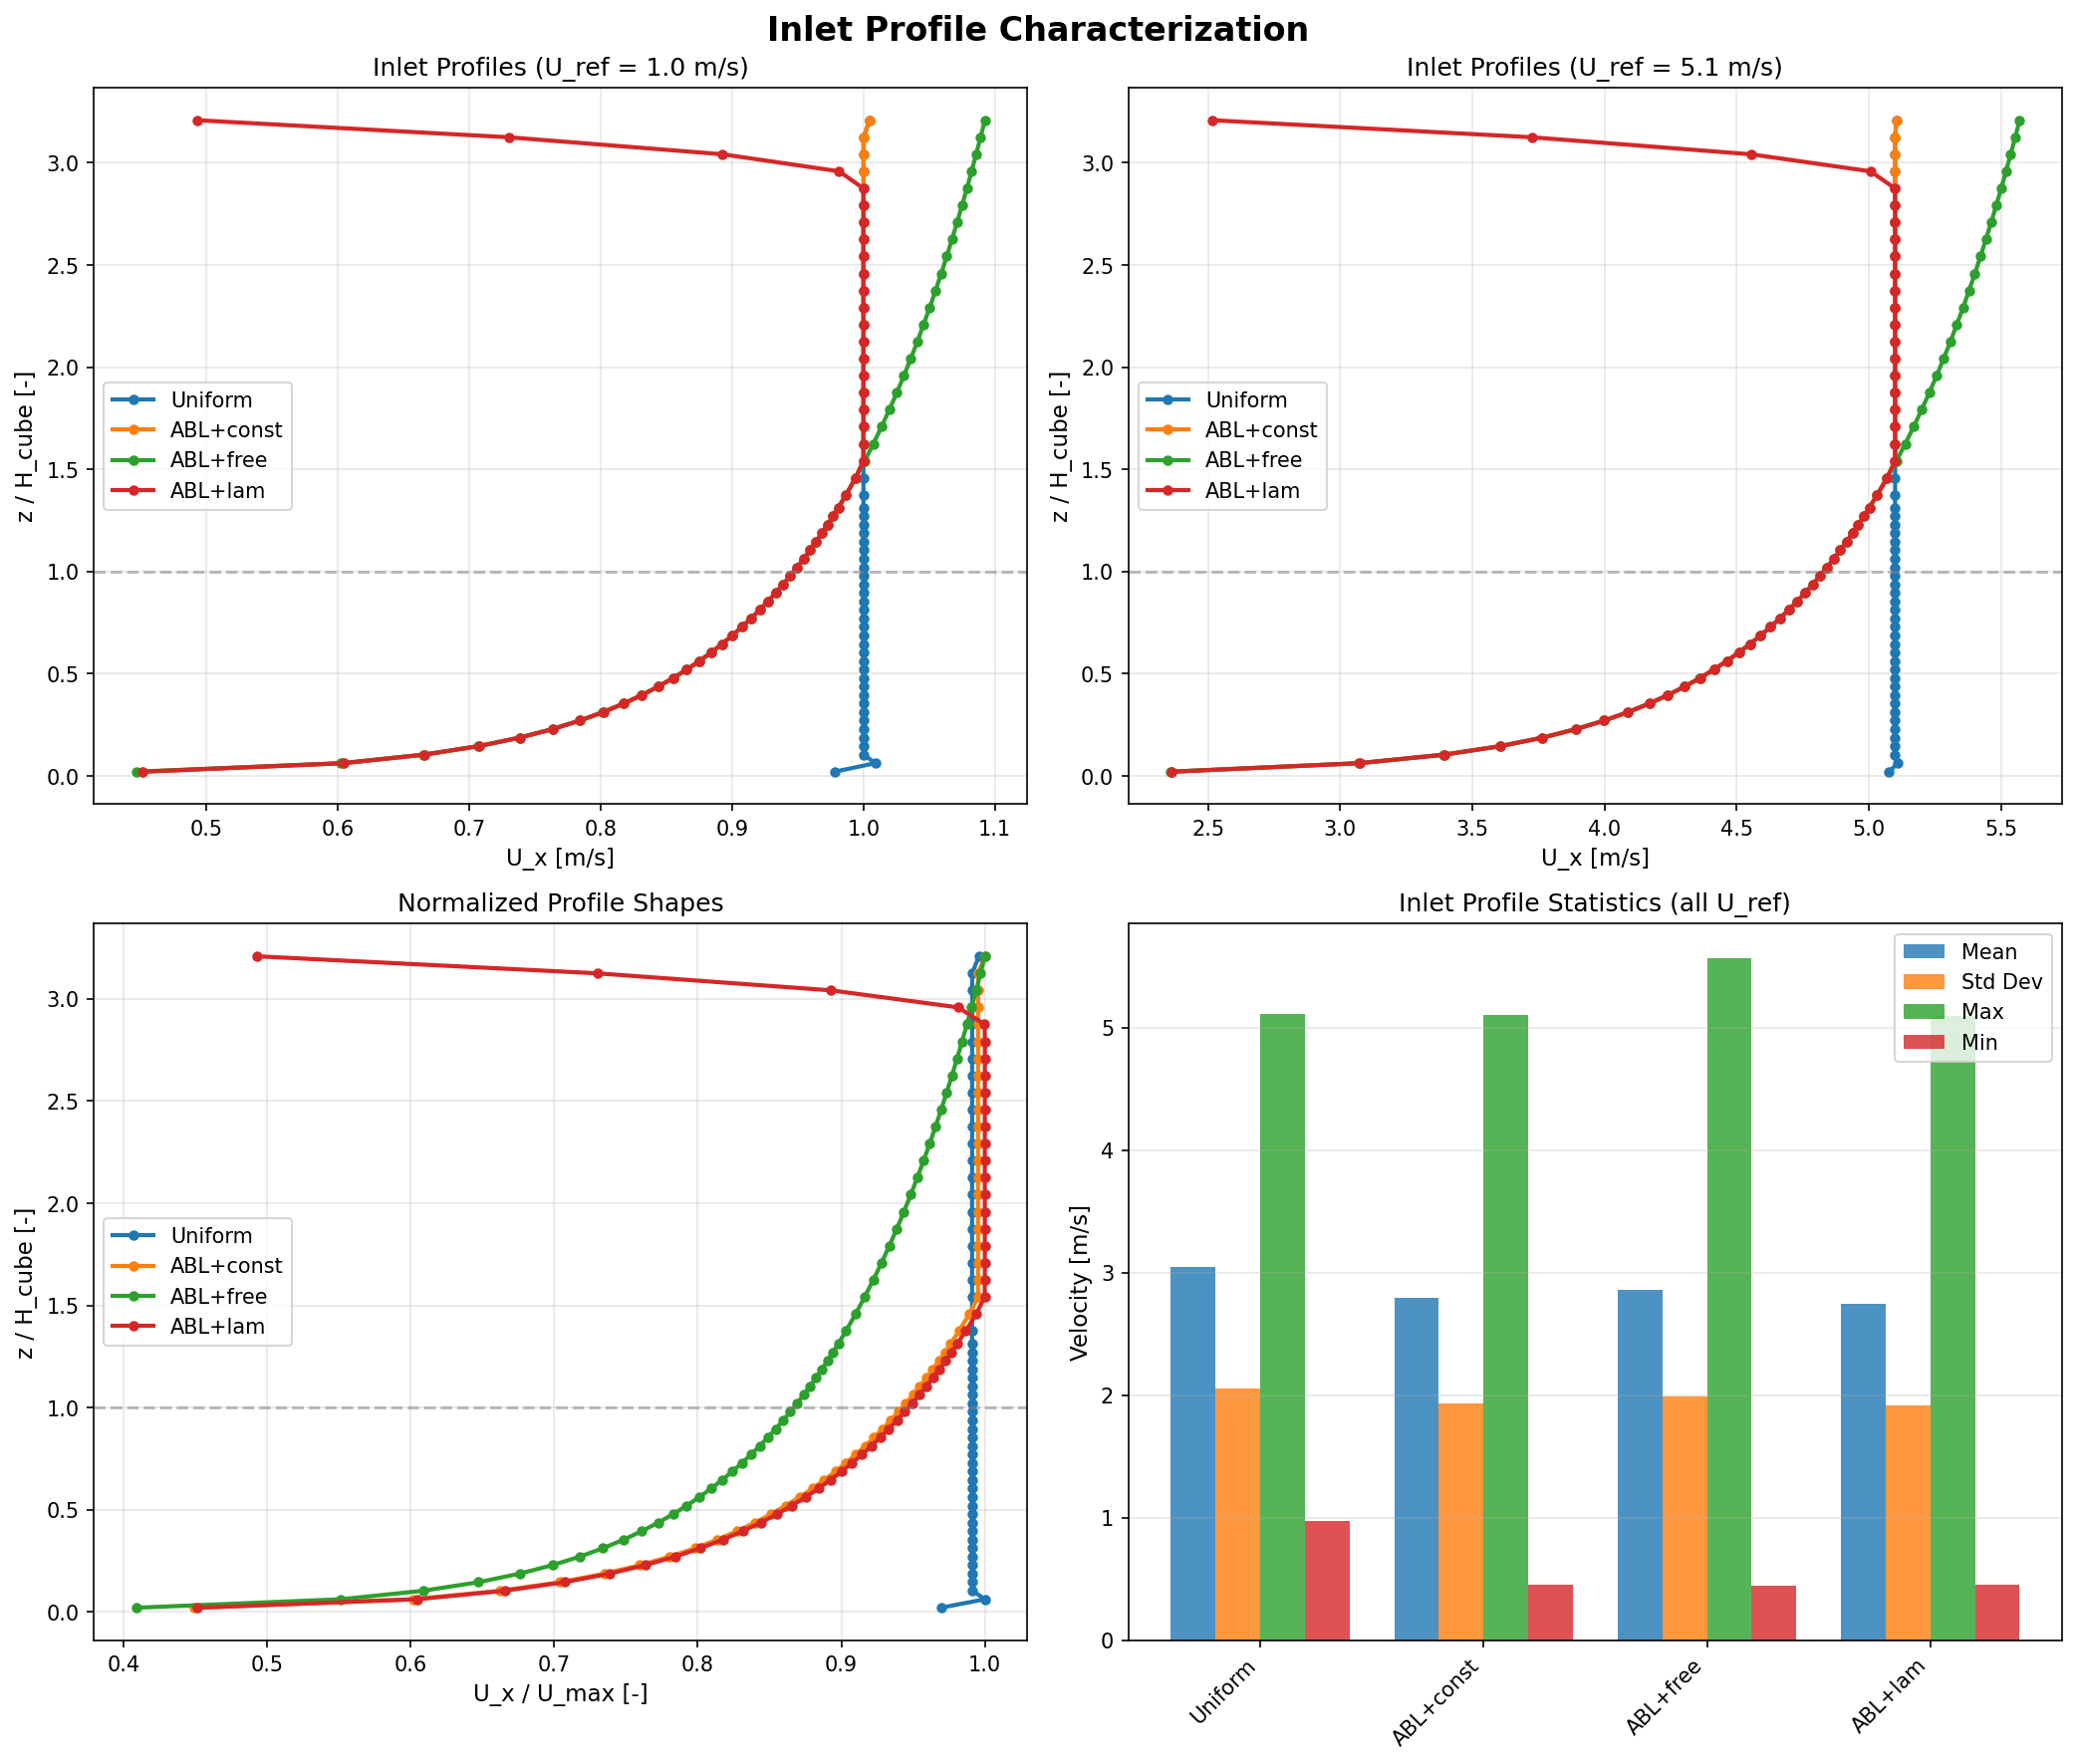

✓ Saved: step2_7_inlet_profiles.png

Profile statistics:
  profile  mean_Ux   std_Ux  max_Ux   min_Ux
  Uniform 3.049883 2.059380 5.10985 0.978107
ABL+const 2.799659 1.936313 5.10515 0.451466
 ABL+free 2.859886 1.990621 5.57112 0.446612
  ABL+lam 2.749578 1.914936 5.10008 0.451462


In [11]:
# ============================================================================
# ANALYSIS 7: INLET PROFILE CHARACTERIZATION
# ============================================================================

print("\n" + "="*80)
print("ANALYSIS 7: INLET PROFILE CHARACTERIZATION")
print("="*80)
print("\nComparing the 4 inlet profile types:")
print("NOTE: Using inlet_type (categorical) instead of α, δ parametrization")

# Extract inlet profiles (x = 0.0)
inlet_data = df[df['x'] == 0.0].copy()

profile_types = sorted(inlet_data['profile_type'].unique())
profile_names_map = {0: 'Uniform', 1: 'ABL+const', 2: 'ABL+free', 3: 'ABL+lam'}

print(f"\nProfile types found: {[profile_names_map[p] for p in profile_types]}")

# Create inlet profile plot
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('Inlet Profile Characterization', fontsize=16, fontweight='bold')

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

# 7.1 Inlet profiles (U_ref = 1.0)
ax = axes[0, 0]
for i, ptype in enumerate(profile_types):
    mask = (inlet_data['profile_type'] == ptype) & (inlet_data['U_ref'] == 1.0)
    data_subset = inlet_data[mask].sort_values('z')
    if len(data_subset) > 0:
        ax.plot(data_subset['U_x'], data_subset['z_norm'], 
               color=colors[i], linewidth=2, marker='o', markersize=4,
               label=f'{profile_names_map[ptype]}')

ax.set_xlabel('U_x [m/s]')
ax.set_ylabel('z / H_cube [-]')
ax.set_title(f'Inlet Profiles (U_ref = 1.0 m/s)')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5, label='Cube height')

# 7.2 Inlet profiles (U_ref = 5.1)
ax = axes[0, 1]
for i, ptype in enumerate(profile_types):
    mask = (inlet_data['profile_type'] == ptype) & (inlet_data['U_ref'] == 5.1)
    data_subset = inlet_data[mask].sort_values('z')
    if len(data_subset) > 0:
        ax.plot(data_subset['U_x'], data_subset['z_norm'], 
               color=colors[i], linewidth=2, marker='o', markersize=4,
               label=f'{profile_names_map[ptype]}')

ax.set_xlabel('U_x [m/s]')
ax.set_ylabel('z / H_cube [-]')
ax.set_title(f'Inlet Profiles (U_ref = 5.1 m/s)')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)

# 7.3 Profile shape comparison (normalized)
ax = axes[1, 0]
for i, ptype in enumerate(profile_types):
    mask = (inlet_data['profile_type'] == ptype) & (inlet_data['U_ref'] == 1.0)
    data_subset = inlet_data[mask].sort_values('z')
    if len(data_subset) > 0:
        U_normalized = data_subset['U_x'] / data_subset['U_x'].max()
        ax.plot(U_normalized, data_subset['z_norm'], 
               color=colors[i], linewidth=2, marker='o', markersize=4,
               label=f'{profile_names_map[ptype]}')

ax.set_xlabel('U_x / U_max [-]')
ax.set_ylabel('z / H_cube [-]')
ax.set_title('Normalized Profile Shapes')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5, label='Cube top')

# 7.4 Profile statistics
ax = axes[1, 1]
statistics = []
for ptype in profile_types:
    mask = inlet_data['profile_type'] == ptype
    data_subset = inlet_data[mask]
    statistics.append({
        'profile': profile_names_map[ptype],
        'mean_Ux': data_subset['U_x'].mean(),
        'std_Ux': data_subset['U_x'].std(),
        'max_Ux': data_subset['U_x'].max(),
        'min_Ux': data_subset['U_x'].min()
    })

stats_df = pd.DataFrame(statistics)

x_pos = np.arange(len(stats_df))
width = 0.2

ax.bar(x_pos - 1.5*width, stats_df['mean_Ux'], width, label='Mean', alpha=0.8)
ax.bar(x_pos - 0.5*width, stats_df['std_Ux'], width, label='Std Dev', alpha=0.8)
ax.bar(x_pos + 0.5*width, stats_df['max_Ux'], width, label='Max', alpha=0.8)
ax.bar(x_pos + 1.5*width, stats_df['min_Ux'], width, label='Min', alpha=0.8)

ax.set_ylabel('Velocity [m/s]')
ax.set_title('Inlet Profile Statistics (all U_ref)')
ax.set_xticks(x_pos)
ax.set_xticklabels(stats_df['profile'], rotation=45, ha='right')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step2_7_inlet_profiles.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step2_7_inlet_profiles.png")
plt.close()

print("\nProfile statistics:")
print(stats_df.to_string(index=False))

In [12]:
# ============================================================================
# SUMMARY REPORT
# ============================================================================

print("\n" + "="*80)
print("SUMMARY REPORT - UPDATED WITH PHYSICS-BASED FEATURES")
print("="*80)

print(f"""
DATA OVERVIEW:
  • Total data points: {len(df):,}
  • Cases: {len(all_cases_data)}
  • Inlet profiles: {len(profile_types)} types
  • Reference velocities: {df['U_ref'].nunique()}
  • Spatial locations: {df['x'].nunique()} x-locations

PHYSICS-BASED FEATURES:
  • x_norm = x / H_cube (range: {df['x_norm'].min():.1f} to {df['x_norm'].max():.1f} cube heights)
  • z_norm = z / H_cube (range: {df['z_norm'].min():.2f} to {df['z_norm'].max():.2f} cube heights)
  • wake_distance = max(0, (x - X_CUBE_BACK) / H_cube)
  • flow_regime = categorical (upstream/over_cube/wake/far_downstream)

KEY FINDINGS:

1. FEATURE IMPORTANCE (Mutual Information):
   • x_norm (x/H): {mi_scores_1[0]:.3f} ({mi_normalized[0]*100:.1f}%)
   • z_norm (z/H): {mi_scores_1[1]:.3f} ({mi_normalized[1]*100:.1f}%)
   • U_ref: {mi_scores_1[2]:.3f} ({mi_normalized[2]*100:.1f}%)
   • profile_type: {mi_scores_1[3]:.3f} ({mi_normalized[3]*100:.1f}%)
   • wake_distance: {mi_scores_2[4]:.3f} (additional)
   • flow_regime: {mi_scores_3[4]:.3f} (additional)

2. CONDITIONAL ENTROPY:
   • Baseline uncertainty: {H_Ux:.2f} bits
   • With original 4 features: {H_cond_1:.2f} bits ({reduction_pct_1:.1f}% reduction)
   • Adding wake_distance: {H_cond_2:.2f} bits ({reduction_pct_2:.1f}% reduction)
   • Adding flow_regime: {H_cond_3:.2f} bits ({reduction_pct_3:.1f}% reduction)

3. CORRELATION CHECK:
   • x_norm ↔ wake_distance: {corr_matrix.loc['x_norm', 'wake_distance']:.3f}
   • x_norm ↔ flow_regime: {corr_matrix.loc['x_norm', 'flow_regime']:.3f}

RECOMMENDATIONS:

✅ RECOMMENDED FEATURE SET FOR LOCAL MODELS (per z-height):
   [x_norm, U_ref, profile_type_onehot]  → 6 features
   
✅ RECOMMENDED FEATURE SET FOR GLOBAL MODELS (all space):
   [x_norm, z_norm, U_ref, profile_type_onehot]  → 7 features

⚠️ OPTIONAL FEATURES (test if they improve model performance):
   • wake_distance: {'ADD if you see performance issues in wake region' if mi_scores_2[4] > 0.05 else 'SKIP - redundant with x_norm'}
   • flow_regime: {'ADD if you want explicit regime handling' if mi_scores_3[4] > 0.05 else 'SKIP - redundant with x_norm'}

❌ DROPPED FEATURES:
   • alpha_inlet (α): 0% MI - not predictive!
   • delta_inlet (δ): 0% MI - not predictive!
   → Use profile_type (categorical) instead!

NEXT STEPS:
  ✓ Proceed to Step 3 with recommended feature set
  ✓ Local models: 55 models (one per z-height)
  ✓ Features: [x_norm, U_ref, profile_type_onehot]
  ✓ Expect excellent model performance ({reduction_pct_1:.0f}%+ uncertainty reduction)
""")

print("="*80)
print("✓ STEP 2 COMPLETE!")
print("="*80)


SUMMARY REPORT - UPDATED WITH PHYSICS-BASED FEATURES

DATA OVERVIEW:
  • Total data points: 11,000
  • Cases: 8
  • Inlet profiles: 4 types
  • Reference velocities: 2
  • Spatial locations: 25 x-locations

PHYSICS-BASED FEATURES:
  • x_norm = x / H_cube (range: 0.0 to 21.0 cube heights)
  • z_norm = z / H_cube (range: 0.02 to 3.21 cube heights)
  • wake_distance = max(0, (x - X_CUBE_BACK) / H_cube)
  • flow_regime = categorical (upstream/over_cube/wake/far_downstream)

KEY FINDINGS:

1. FEATURE IMPORTANCE (Mutual Information):
   • x_norm (x/H): 0.486 (23.7%)
   • z_norm (z/H): 0.901 (44.0%)
   • U_ref: 0.589 (28.8%)
   • profile_type: 0.072 (3.5%)
   • wake_distance: 0.424 (additional)
   • flow_regime: 0.331 (additional)

2. CONDITIONAL ENTROPY:
   • Baseline uncertainty: 3.73 bits
   • With original 4 features: 0.39 bits (89.5% reduction)
   • Adding wake_distance: 0.36 bits (90.4% reduction)
   • Adding flow_regime: 0.36 bits (90.2% reduction)

3. CORRELATION CHECK:
   • x_norm ↔